# EDA of blacklisted-seeded wallets (illicit-side only)

This notebook profiles the **illicit-side dataset** built from the
`blacklisted_wallets` seed table and the `wallet_hops` traversal. It does not
load, join, or analyse the external licit dataset. The licit EDA is a separate
notebook and pipeline (`1.2_LICIT_EDA.ipynb`).

The notebook is organised in three parts:

1. **Foundation** — setup, raw-table profiling, blacklisted label profiling,
   cohort construction, and derived features.
2. **Evidence by plot type** — continuous distributions, binned and
   zero-inflated distributions, bivariate threshold views, categorical and
   composition views, cross-cohort statistics, and threshold sweeps.
3. **Decisions** — premise, separation, and support checks per rule, followed
   by the artifact manifest.

> **Outputs are intentionally cleared.** Start the local PostgreSQL mirror,
> run `python3 src/scripts/ETL.py --status` to confirm coverage, then
> `Run All`. Every result in this notebook is read-only against the mirror.

## 0. Reading guide

### 0.1 Scope and non-goals

**In scope**

- Profile the four illicit-side source tables.
- Build three disjoint cohorts from the blacklisted-seeded data.
- Define H2, H4, and H6 wallet-level features once.
- Compare the blacklisted cohort against the two in-dataset proxy cohorts.
- Screen rule thresholds and produce machine-readable artifacts.

**Out of scope**

- Loading or joining the external licit dataset.
- Writing to PostgreSQL. `src/scripts/ETL.py` owns every database write.
- Final precision/recall claims. The external licit sample is required for
  that, and it belongs to the licit notebook.

### 0.2 Data boundary

| Item | Rule |
|---|---|
| Source of truth | Local PostgreSQL mirror read through `load_analysis_tables()` |
| Writes | None from this notebook |
| Licit data | Not loaded, not joined, not inferred from an external table |
| Background cohort | In-dataset only; it is **not** a licit control |
| Output directory | `outputs/EDA_ILLICIT/` |

The third cohort is called **background**, not "licit". It is the complement of
the blacklisted and seed-adjacent cohorts inside the seed-derived wallet
universe. It contains counterparties, exchanges, victims, and unknown
positives, so it can only provide a local baseline.

### 0.3 Cohort contract

| Cohort | Definition | Colour | Reading |
|---|---|---|---|
| `blacklisted` | Wallet in `blacklisted_wallets` | dark red | Labelled illicit target |
| `seed_adjacent` | Wallet reached by `wallet_hops` with `min(hop_level) >= 1`, not blacklisted | amber | Traversal proxy; proximity decays with hop level |
| `background` | Wallet in the analysis universe but in neither cohort above | grey | Unlabelled in-dataset baseline |

Priority is **blacklisted > seed_adjacent > background**, so the three cohorts
are disjoint. A blacklisted wallet that also appears in `wallet_hops` stays in
`blacklisted`.

### 0.4 Paired-plot contract

Every core metric is shown as a **four-view block** with identical bins, axis
transform, x-limits, and threshold lines:

```text
┌──────────────────────────────────┬──────────────────────────────────┐
│ A. Combined (all three strata)   │ B. Blacklisted (target)          │
├──────────────────────────────────┼──────────────────────────────────┤
│ C. Seed-adjacent (traversal)     │ D. Background (unlabelled)       │
└──────────────────────────────────┴──────────────────────────────────┘
```

Panel A is the weighted mixture of B, C, and D:

\[
P_{\text{all}} = w_b P_b + w_s P_s + w_n P_n
\]

The weights are reported in §5.7 and repeated in §10.5. At this dataset's
scale the blacklisted cohort is a small share of the pool, so **panel A cannot
stand in for panel B**. The four-view block makes that visible instead of
hiding it.

### 0.5 Navigation index

**By hypothesis**

| Rule | Feature definition | Distributions | Bivariate | Statistics | Sweep |
|---|---|---|---|---|---|
| H2 (S2) | §5.2 | §6.1–6.5, §7.1–7.2 | §8.1 | §10 | §11.1–11.2 |
| H4 (S4) | §5.3 | §6.6, §7.3–7.5 | §8.2 | §10 | §11.3 |
| H6 (S6) | §5.4 | §6.7–6.9, §7.6 | §8.3 | §10 | §11.4 |

**By plot type**

| Plot type | Section |
|---|---|
| Histogram + KDE | §6 |
| Ordered bins / zero-inflated bars | §7 |
| Hexbin / threshold quadrant | §8 |
| Categorical and composition bars | §9 |
| Quantiles, box/violin, tests | §10 |
| Threshold-sweep lines | §11 |
| Verdict tables | §12 |

## Part I — Foundation

## 1. Setup

### 1.1. Imports

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import FuncFormatter
from scipy.stats import mannwhitneyu, ks_2samp

warnings.filterwarnings("ignore")

### 1.2. Project paths and output variants

In [2]:
from pathlib import Path

# Resolve the repository root even when Jupyter is launched elsewhere.
CWD = Path().cwd().resolve()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
while not (PROJECT_ROOT / "pyproject.toml").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

ROOT = PROJECT_ROOT / "src"
SRC = PROJECT_ROOT / "datasets"
OUTPUT = PROJECT_ROOT / "outputs"

OUTPUT_VARIANTS = {
    # This notebook owns the illicit-side output only. The licit series has
    # its own notebook and its own output directory.
    "EDA_ILLICIT": OUTPUT / "EDA_ILLICIT",
    "data_cleaning": OUTPUT / "data_cleaning",
    "data_visualization": OUTPUT / "data_visualization",
    "hypothesis_testing": OUTPUT / "hypothesis_testing",
    "threshold_finetuning": OUTPUT / "threshold_finetuning",
    "ETL": OUTPUT / "ETL",
}
EDA_OUTPUT = OUTPUT_VARIANTS["EDA_ILLICIT"]

print(f"project root:    {PROJECT_ROOT}")
print(f"dataset folder:  {SRC}")
print(f"illicit output:  {EDA_OUTPUT}")

project root:    /home/annoy/projects/team/capstone-1/dev/data_analysis
dataset folder:  /home/annoy/projects/team/capstone-1/dev/data_analysis/datasets
illicit output:  /home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/EDA_ILLICIT


In [3]:
for directory in OUTPUT_VARIANTS.values():
    directory.mkdir(parents=True, exist_ok=True)
print("Output directories are ready.")

Output directories are ready.


### 1.3. Plot configuration

In [4]:
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Helvetica", "Arial"],
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
    "axes.linewidth": 0.8,
    "axes.edgecolor": "#333333",
    "lines.linewidth": 1.5,
    "patch.linewidth": 0.5,
    "figure.autolayout": True,
})
sns.set_theme(style="whitegrid", palette="deep", font="sans-serif")
print("Plot configuration loaded.")

Plot configuration loaded.


### 1.4. Read-only loader and ingestion gate

`src/scripts/ETL.py` is the only program that writes to PostgreSQL. This
notebook calls `load_analysis_tables()` and reads the local mirror. The cell
below also prints the latest ingestion status so a partial mirror is visible
before the analysis starts.

```bash
# terminal 1 — batch ingestion, up to five workers
python3 src/scripts/ETL.py --workers 5 --batch-size 50000

# terminal 2 — inspect progress without interrupting ingestion
python3 src/scripts/ETL.py --status
```

In [5]:
from src.scripts.etl.ingest import load_analysis_tables, print_ingestion_status

mirror_status = print_ingestion_status()
if not mirror_status.empty and (mirror_status["status"] != "completed").any():
    print("WARNING: ETL is incomplete; results below are provisional.")

started_at = time.time()
(
    suspicious_account_data,
    suspicious_transactions_data,
    suspicious_blacklisted_data,
    suspicious_wallet_hops_data,
) = load_analysis_tables()
print(f"Loaded analysis tables in {time.time() - started_at:.2f}s.")

all_dfs = [
    suspicious_account_data,
    suspicious_transactions_data,
    suspicious_blacklisted_data,
    suspicious_wallet_hops_data,
]
all_dfs_name = [
    "suspicious_account_data",
    "suspicious_transactions_data",
    "suspicious_blacklisted_data",
    "suspicious_wallet_hops_data",
]

         table_name  source_rows  ingested_rows  progress_percent    status
blacklisted_wallets      11418.0        11418.0             100.0 completed
Loaded analysis tables in 368.47s.


### 1.5. Small shared helpers

In [6]:
BOLD_RED_START = "\033[1;31m"
BOLD_END = "\033[0m"


def bold_text(text: str) -> str:
    """Return text wrapped in a red terminal highlight."""
    return f"{BOLD_RED_START}{text}{BOLD_END}"


def df_col_unique_val_count(df: pd.DataFrame) -> None:
    """Print cardinality and small value sets for every column in a table."""
    print(f"==================== unique values in {id(df):x} ====================")
    for column in df.columns:
        unique_count = df[column].nunique()
        print(f"{column}: {bold_text(str(unique_count)) if unique_count <= 5 else unique_count}")
        if unique_count <= 10:
            print(f"  values: {df[column].unique()}")

### 1.6. Constants, cohort contract, and metric registry

All thresholds, bin edges, cohort names, and colours live here. The analysis
cells below never hard-code a rule value or a cohort label.

In [7]:
# --- Time ---------------------------------------------------------------
SECONDS_PER_MINUTE = 60
MINUTES_PER_HOUR = 60
SECONDS_PER_HOUR = SECONDS_PER_MINUTE * MINUTES_PER_HOUR
HOURS_PER_DAY = 24
SECONDS_PER_DAY = SECONDS_PER_HOUR * HOURS_PER_DAY
NANOS_PER_SECOND = 1_000_000_000
PERCENT = 100

# --- Rule thresholds (docs/hypothesis.md) -------------------------------
H2_LIFETIME_DAYS_MAX = 7.0
H2_BURST_RATIO_MIN = 0.75
H2_MIN_USDT_EVENTS = 5
H4_JACCARD_INDEX_MIN = 0.50
H6_EVENT_COUNT_MIN = 5
H6_CV_DELTA_T_MAX = 0.15

# --- Validation / display ----------------------------------------------
USDT_CONTRACT_ADDRESS = "TR7NHqjeKQxGTCi8q8ZY4pL8otSzgjLj6t"
DAYS_PER_MONTH_APPROX = 30
DAYS_PER_QUARTER_APPROX = 90
LIFETIME_CLIP_DAYS = 30
CV_CLIP_QUANTILE = 0.99
CV_PLOT_CLIP = 5.0

# --- Statistics ---------------------------------------------------------
MIN_GROUP_SIZE = 30
ALPHA = 0.05

# --- Ordered bins -------------------------------------------------------
LIFETIME_BIN_EDGES_DAYS = [
    -0.001,
    1 / HOURS_PER_DAY,
    1,
    H2_LIFETIME_DAYS_MAX,
    DAYS_PER_MONTH_APPROX,
    DAYS_PER_QUARTER_APPROX,
    np.inf,
]
LIFETIME_BIN_LABELS = ["<1h", "1h-1d", "1-7d", "7-30d", "30-90d", ">90d"]
EVENT_COUNT_BIN_EDGES = [0, 1, 4, 9, 49, 99, np.inf]
EVENT_COUNT_BIN_LABELS = ["1", "2-4", "5-9", "10-49", "50-99", "100+"]
TRX_FUNDER_BIN_EDGES = [-0.1, 0, 1, 4, 9, 49, np.inf]
TRX_FUNDER_BIN_LABELS = ["0", "1", "2-4", "5-9", "10-49", "50+"]
JACCARD_BIN_EDGES = [-np.inf, 0, 0.499999999, np.inf]
JACCARD_BIN_LABELS = ["J = 0", "0 < J < 0.5", "J >= 0.5"]
HOP_BIN_EDGES = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5]
HOP_BIN_LABELS = ["hop 0", "hop 1", "hop 2", "hop 3", "hop 4", "hop 5"]

print("Constants loaded.")

Constants loaded.


In [8]:
# --- Cohort contract ----------------------------------------------------
COHORT_BLACKLISTED = "blacklisted"
COHORT_SEED_ADJACENT = "seed_adjacent"
COHORT_BACKGROUND = "background"
COHORT_ORDER = [COHORT_BLACKLISTED, COHORT_SEED_ADJACENT, COHORT_BACKGROUND]

COHORT_LABELS = {
    COHORT_BLACKLISTED: "Blacklisted (labelled illicit)",
    COHORT_SEED_ADJACENT: "Seed-adjacent (traversal)",
    COHORT_BACKGROUND: "Background (unlabelled, in-dataset)",
}
COHORT_COLORS = {
    COHORT_BLACKLISTED: "#B91C1C",
    COHORT_SEED_ADJACENT: "#D97706",
    COHORT_BACKGROUND: "#6B7280",
}
THRESHOLD_COLOR = "#7F1D1D"

print("Cohort contract loaded:", COHORT_ORDER)

Cohort contract loaded: ['blacklisted', 'seed_adjacent', 'background']


In [9]:
# --- Metric registry ----------------------------------------------------
# One place for every plot parameter. The four-view helpers read this dict,
# so panels cannot drift in bins, transform, or threshold.
METRIC_SPECS = {
    "tx_lifetime_days": {
        "kind": "hist",
        "title": "H2 | Wallet lifetime (transaction-derived)",
        "xlabel": "Wallet lifetime (days)",
        "transform": "log1p",
        "bins": 40,
        "threshold": H2_LIFETIME_DAYS_MAX,
        "threshold_label": "7-day threshold",
        "palette": "H2",
    },
    "burst_ratio": {
        "kind": "hist",
        "title": "H2 | Burst ratio = max 1h volume / total volume",
        "xlabel": "Burst ratio",
        "transform": None,
        "bins": 40,
        "threshold": H2_BURST_RATIO_MIN,
        "threshold_label": "75% threshold",
        "palette": "H2",
    },
    "total_volume_usdt": {
        "kind": "hist",
        "title": "H2 | Total USDT volume per wallet",
        "xlabel": "Total USDT volume",
        "transform": "log10",
        "bins": 45,
        "palette": "H2",
    },
    "max_1h_volume_usdt": {
        "kind": "hist",
        "title": "H2 | Maximum 1-hour USDT volume per wallet",
        "xlabel": "Max 1-hour USDT volume",
        "transform": "log10",
        "bins": 45,
        "palette": "H2",
    },
    "usdt_event_count": {
        "kind": "hist",
        "title": "H2 | USDT activity count per wallet",
        "xlabel": "USDT events per wallet",
        "transform": "log10",
        "bins": 40,
        "threshold": H2_MIN_USDT_EVENTS,
        "threshold_label": "N >= 5",
        "palette": "H2",
    },
    "jaccard_index": {
        "kind": "hist",
        "title": "H4 | Jaccard index of TRX funders vs USDT recipients",
        "xlabel": "Jaccard index",
        "transform": None,
        "bins": 40,
        "threshold": H4_JACCARD_INDEX_MIN,
        "threshold_label": "0.50 threshold",
        "palette": "H4",
    },
    "event_count": {
        "kind": "hist",
        "title": "H6 | Transaction events per wallet",
        "xlabel": "Events per wallet",
        "transform": "log10",
        "bins": 40,
        "threshold": H6_EVENT_COUNT_MIN,
        "threshold_label": "N >= 5",
        "palette": "H6",
    },
    "cv_delta_t": {
        "kind": "hist",
        "title": "H6 | Coefficient of variation of inter-arrival times",
        "xlabel": "CV(delta t)",
        "transform": None,
        "bins": 45,
        "clip_quantile": CV_CLIP_QUANTILE,
        "threshold": H6_CV_DELTA_T_MAX,
        "threshold_label": "CV < 0.15",
        "palette": "H6",
    },
    "mean_delta_minutes": {
        "kind": "hist",
        "title": "H6 | Mean inter-arrival time per wallet",
        "xlabel": "Mean inter-arrival time (minutes)",
        "transform": "log10",
        "bins": 45,
        "palette": "H6",
    },
    "tx_lifetime_binned": {
        "kind": "binned",
        "source": "tx_lifetime_days",
        "title": "H2 | Wallet lifetime ranges",
        "xlabel": "Lifetime range",
        "bins": LIFETIME_BIN_EDGES_DAYS,
        "labels": LIFETIME_BIN_LABELS,
        "palette": "H2",
    },
    "usdt_event_count_binned": {
        "kind": "binned",
        "source": "usdt_event_count",
        "title": "H2 | USDT activity ranges",
        "xlabel": "USDT events per wallet",
        "bins": EVENT_COUNT_BIN_EDGES,
        "labels": EVENT_COUNT_BIN_LABELS,
        "palette": "H2",
    },
    "trx_funder_count_binned": {
        "kind": "binned",
        "source": "trx_funder_count",
        "title": "H4 | Distinct TRX funders per wallet",
        "xlabel": "TRX funders",
        "bins": TRX_FUNDER_BIN_EDGES,
        "labels": TRX_FUNDER_BIN_LABELS,
        "palette": "H4",
    },
    "usdt_recipient_count_binned": {
        "kind": "binned",
        "source": "usdt_recipient_count",
        "title": "H4 | Distinct USDT recipients per wallet",
        "xlabel": "USDT recipients",
        "bins": TRX_FUNDER_BIN_EDGES,
        "labels": TRX_FUNDER_BIN_LABELS,
        "palette": "H4",
    },
    "jaccard_index_binned": {
        "kind": "binned",
        "source": "jaccard_index",
        "title": "H4 | Jaccard index ranges",
        "xlabel": "Jaccard range",
        "bins": JACCARD_BIN_EDGES,
        "labels": JACCARD_BIN_LABELS,
        "palette": "H4",
    },
    "event_count_binned": {
        "kind": "binned",
        "source": "event_count",
        "title": "H6 | Wallet activity count ranges",
        "xlabel": "Events per wallet range",
        "bins": EVENT_COUNT_BIN_EDGES,
        "labels": EVENT_COUNT_BIN_LABELS,
        "palette": "H6",
    },
}
print(f"Metric registry loaded: {len(METRIC_SPECS)} entries.")

Metric registry loaded: 15 entries.


### 1.7. Plot helpers

In [10]:
import colorsys


def hsl_to_hex(hue, saturation, lightness):
    """Convert HSL (degrees, %, %) to a hex colour."""
    r, g, b = colorsys.hls_to_rgb(hue / 360.0, lightness / 100.0, saturation / 100.0)
    return "#{:02X}{:02X}{:02X}".format(
        int(round(r * 255)), int(round(g * 255)), int(round(b * 255))
    )


def monochromatic_palette(hue, saturation=65, lightness=(26, 40, 54, 70, 84)):
    """Five named levels of one hue, darkest to lightest."""
    levels = ["darkest", "dark", "mid", "light", "lightest"]
    return {
        name: hsl_to_hex(hue, saturation, value)
        for name, value in zip(levels, lightness)
    }


def monochromatic_sequence(hue, n, saturation=65, lightness_start=84, lightness_end=32):
    """Sequential tint ramp for ordered bins (light to dark)."""
    return [
        hsl_to_hex(hue, saturation, value)
        for value in np.linspace(lightness_start, lightness_end, n)
    ]


def monochromatic_cmap(hue):
    """Light-to-dark sequential colormap for density plots."""
    return LinearSegmentedColormap.from_list(
        f"hue_{hue}", [hsl_to_hex(hue, 45, 94), hsl_to_hex(hue, 75, 28)]
    )


H2_HUE, H4_HUE, H6_HUE = 32, 174, 217
HYPOTHESIS_PALETTES = {
    "H2": {"mono": monochromatic_palette(H2_HUE), "accent": hsl_to_hex(212, 62, 46)},
    "H4": {
        "mono": monochromatic_palette(H4_HUE),
        "complement": hsl_to_hex(354, 72, 48),
        "token": {"USDT": hsl_to_hex(174, 68, 44), "TRX": hsl_to_hex(354, 72, 52)},
        "pattern": {
            "Both": hsl_to_hex(354, 72, 50),
            "TRX funder only": hsl_to_hex(174, 68, 38),
            "USDT recipient only": hsl_to_hex(174, 58, 66),
            "Neither": "#9CA3AF",
        },
    },
    "H6": {"mono": monochromatic_palette(H6_HUE), "accent": hsl_to_hex(197, 62, 46)},
}
print("Colour system loaded.")

Colour system loaded.


In [11]:
def compact_number(value):
    """Human-readable axis tick or marker label."""
    if pd.isna(value):
        return "NA"
    if value == 0:
        return "0"
    absolute = abs(value)
    if absolute >= 1e9:
        return f"{value / 1e9:.2f}B"
    if absolute >= 1e6:
        return f"{value / 1e6:.2f}M"
    if absolute >= 1e3:
        return f"{value / 1e3:.2f}k"
    if absolute >= 1:
        return f"{value:.3g}"
    return f"{value:.2g}"


def transform_value(value, transform):
    """Apply the axis transform to a raw value."""
    if transform == "log10":
        return np.log10(value)
    if transform == "log1p":
        return np.log1p(value)
    return value


def inverse_log_tick(value, transform):
    """Turn a transformed tick back into the original unit."""
    if transform == "log10":
        return compact_number(10 ** value)
    if transform == "log1p":
        return compact_number(np.expm1(value))
    return compact_number(value)


def empty_panel(ax, message="No data in this cohort"):
    """Write a readable placeholder instead of an empty axis."""
    ax.text(0.5, 0.5, message, ha="center", va="center", transform=ax.transAxes)
    ax.set_xticks([])
    ax.set_yticks([])


def cohort_subset(table, cohort):
    """Select one cohort without repeating the boolean mask everywhere."""
    return table.loc[table["cohort"] == cohort]


COHORT_PANELS = [
    ("A. Combined (all three strata)", None),
    ("B. Blacklisted (target)", COHORT_BLACKLISTED),
    ("C. Seed-adjacent (traversal)", COHORT_SEED_ADJACENT),
    ("D. Background (unlabelled)", COHORT_BACKGROUND),
]

In [12]:
def draw_histogram(ax, series, *, title, spec, show_legend=True):
    """Draw one histogram + KDE panel with mean, median, and threshold markers."""
    palette = HYPOTHESIS_PALETTES[spec["palette"]]["mono"]
    values = pd.Series(series).dropna().astype(float)
    n_total = len(values)
    n_zero = int((values == 0).sum())
    transform = spec.get("transform")

    if transform == "log10":
        values_plot = values[values > 0]
        plot_values = np.log10(values_plot)
    elif transform == "log1p":
        values_plot = values[values >= 0]
        plot_values = np.log1p(values_plot)
    else:
        values_plot = values
        plot_values = values

    clipped_count = 0
    clip_quantile = spec.get("clip_quantile")
    if clip_quantile is not None and len(plot_values):
        upper = plot_values.quantile(clip_quantile)
        keep = plot_values <= upper
        clipped_count = int((~keep).sum())
        plot_values = plot_values[keep]

    if len(plot_values) == 0:
        empty_panel(ax)
        ax.set_title(title, fontsize=11)
        return

    sns.histplot(
        plot_values,
        bins=spec["bins"],
        kde=(plot_values.nunique() > 1),
        color=palette["mid"],
        edgecolor="white",
        alpha=0.78,
        ax=ax,
    )

    if len(values_plot):
        mean_value = values_plot.mean()
        median_value = values_plot.median()
        ax.axvline(
            transform_value(mean_value, transform),
            color=palette["darkest"],
            linewidth=2.0,
            linestyle="-",
            label=f"Mean = {compact_number(mean_value)}",
        )
        ax.axvline(
            transform_value(median_value, transform),
            color=palette["dark"],
            linewidth=2.0,
            linestyle="--",
            label=f"Median = {compact_number(median_value)}",
        )

    if spec.get("threshold") is not None:
        ax.axvline(
            transform_value(spec["threshold"], transform),
            color=THRESHOLD_COLOR,
            linewidth=1.8,
            linestyle=":",
            label=spec.get("threshold_label", f"Threshold = {spec['threshold']}"),
        )

    if transform in ("log10", "log1p"):
        ax.xaxis.set_major_formatter(
            FuncFormatter(lambda value, _: inverse_log_tick(value, transform))
        )

    suffix = " (log10 scale)" if transform == "log10" else (
        " (log1p scale)" if transform == "log1p" else ""
    )
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(f"{spec['xlabel']}{suffix}")
    ax.set_ylabel("Frequency")
    if show_legend:
        ax.legend(loc="upper right", frameon=True, fontsize=8)

    note = f"n = {n_total:,}"
    if transform == "log10" and n_zero:
        note += f" | zero excluded: {n_zero:,} ({n_zero / n_total:.1%})"
    if transform == "log1p" and n_zero:
        note += f" | zeros kept: {n_zero:,} ({n_zero / n_total:.1%})"
    if clipped_count:
        note += f" | clipped: {clipped_count:,} ({clipped_count / n_total:.1%})"
    ax.text(
        0.01,
        0.97,
        note,
        transform=ax.transAxes,
        va="top",
        fontsize=8,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#D1D5DB", alpha=0.88),
    )


def draw_binned_bar(ax, series, *, title, spec):
    """Draw one ordered-bin bar panel with count and share labels."""
    values = pd.Series(series).dropna().astype(float)
    if len(values) == 0:
        empty_panel(ax)
        ax.set_title(title, fontsize=11)
        return

    binned = pd.cut(
        values, bins=spec["bins"], labels=spec["labels"], right=True, include_lowest=True
    )
    counts = binned.value_counts().reindex(spec["labels"]).fillna(0).astype(int)
    # Use the hypothesis hue, not a hard-coded hue.
    hue = {"H2": H2_HUE, "H4": H4_HUE, "H6": H6_HUE}[spec["palette"]]
    colors = monochromatic_sequence(hue, len(spec["labels"]))
    bars = ax.bar(range(len(counts)), counts.values, color=colors, edgecolor="white")
    total = counts.sum()
    for bar, count in zip(bars, counts.values):
        share = count / total * 100 if total else 0
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{count:,}\n({share:.1f}%)",
            ha="center",
            va="bottom",
            fontsize=7,
        )
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(spec["xlabel"])
    ax.set_ylabel("Wallets")
    ax.set_xticks(range(len(counts)))
    ax.set_xticklabels(spec["labels"])
    ax.set_ylim(0, max(counts.values) * 1.20 if len(counts) else 1)
    ax.text(
        0.01,
        0.97,
        f"n = {total:,}",
        transform=ax.transAxes,
        va="top",
        fontsize=8,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#D1D5DB", alpha=0.88),
    )


def four_view_histogram(metric_key, table, *, suptitle=None):
    """Render panels A-D for one continuous metric with shared axes."""
    spec = METRIC_SPECS[metric_key]
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
    for ax, (title, cohort) in zip(axes.ravel(), COHORT_PANELS):
        subset = table if cohort is None else cohort_subset(table, cohort)
        draw_histogram(
            ax,
            subset[metric_key],
            title=title,
            spec=spec,
            show_legend=(ax is axes[0, 0]),
        )
    fig.suptitle(suptitle or spec["title"], fontsize=14)
    fig.tight_layout()
    plt.show()


def four_view_binned(metric_key, table, *, suptitle=None):
    """Render panels A-D for one ordered-bin metric with shared axes."""
    spec = METRIC_SPECS[metric_key]
    source = spec["source"]
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
    for ax, (title, cohort) in zip(axes.ravel(), COHORT_PANELS):
        subset = table if cohort is None else cohort_subset(table, cohort)
        draw_binned_bar(ax, subset[source], title=title, spec=spec)
    fig.suptitle(suptitle or spec["title"], fontsize=14)
    fig.tight_layout()
    plt.show()

## 2. Raw-table foundation

### 2.1. Table inventory and schema

This section is intentionally group-agnostic: it checks the shape and quality
of the four source tables before any cohort is assigned.

In [13]:
inventory = pd.DataFrame({
    "table": all_dfs_name,
    "rows": [len(df) for df in all_dfs],
    "columns": [df.shape[1] for df in all_dfs],
    "null_cells": [int(df.isna().sum().sum()) for df in all_dfs],
    "duplicate_rows": [int(df.duplicated().sum()) for df in all_dfs],
})
inventory["null_share"] = inventory["null_cells"] / (inventory["rows"] * inventory["columns"])
display(inventory.style.format({"rows": "{:,}", "null_share": "{:.2%}"}))

,table,rows,columns,null_cells,duplicate_rows,null_share
0,suspicious_account_data,"2,125,343",6,8004416,0,62.77%
1,suspicious_transactions_data,"5,023,780",10,2631394,0,5.24%
2,suspicious_blacklisted_data,"11,418",8,9888,0,10.83%
3,suspicious_wallet_hops_data,"1,736,551",8,974,0,0.01%


### 2.2. `suspicious_account_data`

In [14]:
# Read data
suspicious_account_data.sample(5)

,address,hex_address,first_seen_timestamp,last_seen_timestamp,created_date,created_at
533985,TEmXnqP66Gqv2vF6kbEK4gZUPfVyzP1cdP,NaN,NaT,NaT,NaT,2026-11-06 14:50:12.837924+00:00
978434,TPuXXimJpmoakUmDUZpy9w47oCJWMbVahR,NaN,NaT,NaT,NaT,2026-11-07 00:09:09.775713+00:00
1427878,TCvECzRv3xJVbMFJ2ZgLxJffFM6qNByfko,NaN,NaT,NaT,NaT,2026-10-29 05:02:11.164451+00:00
976633,TPS1wiRSHhP1RzRyDQMtpnSJPkbSGD9ktd,NaN,NaT,NaT,NaT,2026-11-07 17:12:06.295164+00:00
1448566,TDzLs7rVZZcxkBiJjdxvEWogrYvm8dAdFU,NaN,NaT,NaT,NaT,2026-11-04 23:10:02.590970+00:00


In [15]:
suspicious_account_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2125343 entries, 0 to 2125342
Data columns (total 6 columns):
 #   Column                Dtype              
---  ------                -----              
 0   address               str                
 1   hex_address           str                
 2   first_seen_timestamp  datetime64[us, UTC]
 3   last_seen_timestamp   datetime64[us, UTC]
 4   created_date          datetime64[us, UTC]
 5   created_at            datetime64[us, UTC]
dtypes: datetime64[us, UTC](4), str(2)
memory usage: 97.3 MB


In [16]:
suspicious_account_data.describe()

,address,hex_address,first_seen_timestamp,last_seen_timestamp,created_date,created_at
count,2125343,8946,164474,159062,164474,2125343
unique,2125343,8946,NaN,NaN,NaN,NaN
top,T9yacXTw2mWQrPbRd7YKARhVXcMoKfH3FY,0x0000000000000000000000000000000000555534,NaN,NaN,NaN,NaN
freq,1,1,NaN,NaN,NaN,NaN
mean,NaN,NaN,2025-01-14 18:02:45.362154+00:00,2025-02-04 05:15:48.875187+00:00,2025-01-14 18:02:45.362154+00:00,2026-11-03 17:21:37.759264+00:00
min,NaN,NaN,2019-09-26 08:41:51+00:00,2020-09-24 14:37:39+00:00,2019-09-26 08:41:51+00:00,2026-10-28 14:15:20.965029+00:00
25%,NaN,NaN,2024-02-02 11:27:09+00:00,2024-03-03 10:32:27.750000+00:00,2024-02-02 11:27:09+00:00,2026-10-29 09:06:28.950680+00:00
50%,NaN,NaN,2025-04-11 04:26:52.500000+00:00,2025-05-16 07:43:45+00:00,2025-04-11 04:26:52.500000+00:00,2026-11-05 19:02:11.402869+00:00
75%,NaN,NaN,2026-02-19 02:25:21+00:00,2026-02-20 19:40:42+00:00,2026-02-19 02:25:21+00:00,2026-11-06 17:55:19.827237+00:00
max,NaN,NaN,2026-11-04 21:14:51+00:00,2026-10-29 07:43:33+00:00,2026-11-04 21:14:51+00:00,2026-11-07 22:02:44.271835+00:00


In [17]:
df_col_unique_val_count(suspicious_account_data)

==================== unique values in 7f917daac510 ====================
address: 2125343
hex_address: 8946
first_seen_timestamp: 156172
last_seen_timestamp: 151439
created_date: 156172
created_at: 54182


### 2.3. `suspicious_blacklisted_data`

In [18]:
suspicious_blacklisted_data.sample(5)

,wallet_address,hex_address,blacklisted_timestamp,blacklisted_utc,transaction_id,source_name,label,created_at
8257,TSzAgwR8G4u3RhtAJJxunYKmfCXhBzYErh,0xbaa89fbd2ff4326b014b44e4e147c963e620e92d,1.702076e+09,2023-12-08 22:52:54+00:00,556b4cf415002c9523bb2bfcce989050d8abc62447a9f4...,TronScan,1,2026-10-28 14:16:13.287964+00:00
11169,TYu9nMAjDcY1AHXadrJDvUVUfJ9mok42B3,0xfb868abeadfd74364a5b29fb72e2d76f2a539530,1.761865e+09,2025-10-30 22:55:48+00:00,111ca7fc8cd4b65f51eaae313b20a112c31ce787b56f19...,TronScan,1,2026-10-28 14:16:13.287964+00:00
3004,TFyoPxafg4nejQU1FW5hmrzS24Q1PVy5Zj,0x41ed774fba4065899285477bd7422ce65b7214d8,1.743806e+09,2025-04-04 22:36:54+00:00,e1fdf60aa82b3835ccb196ff00eb6ed574d0e92c5d67cf...,TronScan,1,2026-10-28 14:16:13.287964+00:00
2584,TFa7npjkzvaJShy6UADMzTjX3FAtC4za4d,NaN,NaN,NaT,NaN,TronScan,1,2026-11-05 21:45:19.403452+00:00
7127,TQmtPP1g4t87ehYcYgm434xfQmVun9db8s,0xa265c5a3ef8395b14e31f888e3c2228a17cea4dc,1.764838e+09,2025-12-04 08:48:24+00:00,55be93c6a64fe0b1f0c2a879c9144382f7c0d59988ba24...,TronScan,1,2026-10-28 14:16:13.287964+00:00


In [19]:
suspicious_blacklisted_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 11418 entries, 0 to 11417
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   wallet_address         11418 non-null  str                
 1   hex_address            8946 non-null   str                
 2   blacklisted_timestamp  8946 non-null   float64            
 3   blacklisted_utc        8946 non-null   datetime64[us, UTC]
 4   transaction_id         8946 non-null   str                
 5   source_name            11418 non-null  str                
 6   label                  11418 non-null  int64              
 7   created_at             11418 non-null  datetime64[us, UTC]
dtypes: datetime64[us, UTC](2), float64(1), int64(1), str(4)
memory usage: 713.8 KB


In [20]:
suspicious_blacklisted_data.describe()

,blacklisted_timestamp,label
count,8.946000e+03,11418.0
mean,1.754078e+09,1.0
std,3.071763e+07,0.0
min,1.593185e+09,1.0
25%,1.741112e+09,1.0
50%,1.757099e+09,1.0
75%,1.776698e+09,1.0
max,1.792459e+09,1.0


In [21]:
suspicious_blacklisted_data.describe(include="str")

,wallet_address,hex_address,transaction_id,source_name
count,11418,8946,8946,11418
unique,11418,8946,8946,1
top,T9yb6vP8o8PQJLNmcCkC9wfk73ULTCy2MB,0x001272f4ae1a38f345bfeb880fdb51a414720821,84caecac41da1bb63e8697d54a844bce3b6b3e8e47cb30...,TronScan
freq,1,1,1,11418


In [22]:
df_col_unique_val_count(suspicious_blacklisted_data)

==================== unique values in 7f917f7d4050 ====================
wallet_address: 11418
hex_address: 8946
blacklisted_timestamp: 7050
blacklisted_utc: 7050
transaction_id: 8946
source_name: 1
  values: <StringArray>
['TronScan']
Length: 1, dtype: str
label: 1
  values: [1]
created_at: 2473


### 2.4. `suspicious_transactions_data`

In [23]:
suspicious_transactions_data.head()

,tx_hash,block_number,block_timestamp,from_address,to_address,token_symbol,contract_address,amount,fee_trx,created_at
0,c7124b8146a4996a85b43bb4f780f583dddd0cf83527a2...,70244036,2025-03-07 22:00:34.024+00:00,TKdeWpMxzZpNYAKMCQZxetFJytCe931Z4L,TQCdiarJzZR5ea4p4pqQ7Ac58DPjpuqZos,TRX,NaN,0.000006,0.0,2026-11-07 13:01:25.282463+00:00
1,4882e470eadc056df2d5b25baba27a6dea17a0928db3cd...,70244037,2025-03-07 22:00:35.638+00:00,TNTtmRYyzycxDknPBokRiVb9kekBwSTZ4L,TQCdiarJzZR5ea4p4pqQ7Ac58DPjpuqZos,TRX,NaN,0.000001,0.0,2026-11-07 13:01:25.282463+00:00
2,4b8ce28ee4e7ccb4cc1761b7dac26a60a12e7fdfcdb5ca...,70244118,2025-03-07 22:04:42.000+00:00,TK9zfjuKEHXQJ5JjHKD3goQw7LAbgcBT4j,TASZMLkP6kjyumeDtGnTFpeJgaahgGDKU8,TRX,NaN,0.000002,0.0,2026-10-29 10:05:37.516419+00:00
3,6a26f4a761f70babf83ed6012a7e2e6c647c998278acee...,70244118,2025-03-07 22:04:42.000+00:00,TH1nBvuZp4hSHKznJLHkqrbAnvYfzfyT4j,TASZMLkP6kjyumeDtGnTFpeJgaahgGDKU8,TRX,NaN,0.000004,0.0,2026-10-29 10:05:37.516419+00:00
4,7d57aed06bbbfb6ea9d9236535c4a5f0ec3574c4db622f...,70244286,2025-03-07 22:13:06.000+00:00,TBAucDsGx2Dt8UhSugx3kK2HF5xcWX2F9o,TASZMLkP6kjyumeDtGnTFpeJgaahgGDKU8,TRX,NaN,0.000004,0.0,2026-10-29 10:05:37.516419+00:00


In [24]:
suspicious_transactions_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5023780 entries, 0 to 5023779
Data columns (total 10 columns):
 #   Column            Dtype              
---  ------            -----              
 0   tx_hash           str                
 1   block_number      int64              
 2   block_timestamp   datetime64[us, UTC]
 3   from_address      str                
 4   to_address        str                
 5   token_symbol      str                
 6   contract_address  str                
 7   amount            float64            
 8   fee_trx           float64            
 9   created_at        datetime64[us, UTC]
dtypes: datetime64[us, UTC](2), float64(2), int64(1), str(5)
memory usage: 383.3 MB


In [25]:
suspicious_transactions_data.describe()

,block_number,amount,fee_trx
count,5.023780e+06,5.023780e+06,5.023780e+06
mean,4.332896e+07,3.708552e+67,5.154757e-03
std,4.188252e+07,2.071916e+69,3.638919e-02
min,0.000000e+00,0.000000e+00,0.000000e+00
25%,0.000000e+00,2.000000e-06,0.000000e+00
50%,5.260044e+07,1.500000e+00,0.000000e+00
75%,8.663140e+07,1.500000e+03,0.000000e+00
max,8.780484e+07,1.157921e+71,9.920000e-01


In [26]:
suspicious_transactions_data.describe(include="str")

,tx_hash,from_address,to_address,token_symbol,contract_address
count,5023780,5023780,5023780,5023780,2392386
unique,5023780,1305727,978079,2,1
top,c7124b8146a4996a85b43bb4f780f583dddd0cf83527a2...,TLaGjwhvA8XQYSxFAcAXy7Dvuue9eGYitv,TDii6vao7xyWg2rKPbCPWVRpSmne8xcqYx,TRX,TR7NHqjeKQxGTCi8q8ZY4pL8otSzgjLj6t
freq,1,23783,86622,2631394,2392386


In [27]:
df_col_unique_val_count(suspicious_transactions_data)

==================== unique values in 7f917daac050 ====================
tx_hash: 5023780
block_number: 1897831
block_timestamp: 4528044
from_address: 1305727
to_address: 978079
token_symbol: 2
  values: <StringArray>
['TRX', 'USDT']
Length: 2, dtype: str
contract_address: 1
  values: <StringArray>
[nan, 'TR7NHqjeKQxGTCi8q8ZY4pL8otSzgjLj6t']
Length: 2, dtype: str
amount: 525926
fee_trx: 127
created_at: 58005


### 2.5. `suspicious_wallet_hops_data`

In [28]:
suspicious_wallet_hops_data.head()

,hop_id,wallet_address,seed_address,parent_address,via_tx_hash,hop_level,direction,discovered_at
0,375056,TQqQgV7trahRqTQbuX8XUoeouAbkjW1XdF,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,ca222f38e4087719c04da484403c370e66fd2a1ff304dc...,1,BACKWARD,2026-11-05 12:31:35.221940+00:00
1,375057,TY89N6Sqa5XGzqMSb7pmgwdF3K8fqjWqf9,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,c197d913cecc8fcfc9618f3f9fa21b4ba4700d1afda925...,1,BACKWARD,2026-11-05 12:31:35.221940+00:00
2,375058,TRFUX6HawhAPTXs3pTH7PocXHB6pHTRof9,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,59fda13bbb797af10d22bc08e318fec64c6276a4063e26...,1,BACKWARD,2026-11-05 12:31:35.221940+00:00
3,375059,TDC7FXs77qF8voypbVWKguHedEnZ7B5Pf9,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,886104f5658f5b3ae012df41cf34139895e027cac24abe...,1,BACKWARD,2026-11-05 12:31:35.221940+00:00
4,375060,TTvXMMRK7e48EeokYpypECt9p6HBBK9rf9,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,0a2261efacaa766a5da8e212792430a7c2300d0c6559c0...,1,BACKWARD,2026-11-05 12:31:35.221940+00:00


In [29]:
suspicious_wallet_hops_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1736551 entries, 0 to 1736550
Data columns (total 8 columns):
 #   Column          Dtype              
---  ------          -----              
 0   hop_id          int64              
 1   wallet_address  str                
 2   seed_address    str                
 3   parent_address  str                
 4   via_tx_hash     str                
 5   hop_level       int64              
 6   direction       str                
 7   discovered_at   datetime64[us, UTC]
dtypes: datetime64[us, UTC](1), int64(2), str(5)
memory usage: 106.0 MB


In [30]:
suspicious_wallet_hops_data.describe()

,hop_id,hop_level
count,1.736551e+06,1.736551e+06
mean,9.321316e+05,3.041380e+00
std,5.432207e+05,1.396449e+00
min,1.810000e+02,0.000000e+00
25%,4.622645e+05,2.000000e+00
50%,9.258630e+05,3.000000e+00
75%,1.406438e+06,4.000000e+00
max,1.874559e+06,5.000000e+00


In [31]:
suspicious_wallet_hops_data.describe(include="str")

,wallet_address,seed_address,parent_address,via_tx_hash,direction
count,1736551,1736551,1736072,1736056,1736551
unique,1342721,5931,30270,1723502,2
top,TDii6vao7xyWg2rKPbCPWVRpSmne8xcqYx,TRRpsDmL4zNT4XFzApCjUyQQJGg3QfCZbC,THQj8UoYDJqs3UWKRv1GeNxifLu18MCahC,2fc4e907b1716d6e36ac46759e4ca02a8bb46f7edcbf13...,BACKWARD
freq,1531,497969,249,50,925394


In [32]:
df_col_unique_val_count(suspicious_wallet_hops_data)

==================== unique values in 7f917dbc9480 ====================
hop_id: 1736551
wallet_address: 1342721
seed_address: 5931
parent_address: 30270
via_tx_hash: 1723502
hop_level: 6
  values: [1 2 3 4 5 0]
direction: 2
  values: <StringArray>
['BACKWARD', 'FORWARD']
Length: 2, dtype: str
discovered_at: 31439


### 2.6. Missingness

In [33]:
null_summary = pd.concat(
    [
        df.isna().sum().rename("nulls").to_frame().assign(table=name)
        for name, df in zip(all_dfs_name, all_dfs)
    ]
)
display(
    null_summary.reset_index()
    .rename(columns={"index": "column"})
    .pivot_table(index="column", columns="table", values="nulls", aggfunc="sum", fill_value=0)
    .astype(int)
)

table,suspicious_account_data,suspicious_blacklisted_data,suspicious_transactions_data,suspicious_wallet_hops_data
column,,,,
address,0,0,0,0
amount,0,0,0,0
blacklisted_timestamp,0,2472,0,0
blacklisted_utc,0,2472,0,0
block_number,0,0,0,0
block_timestamp,0,0,0,0
contract_address,0,0,2631394,0
created_at,0,0,0,0
created_date,1960869,0,0,0


### 2.7. Duplicates and key integrity

In [34]:
duplicate_summary = pd.DataFrame({
    "table": all_dfs_name,
    "duplicate_rows": [int(df.duplicated().sum()) for df in all_dfs],
})
display(duplicate_summary)

for name, df, key in [
    ("accounts", suspicious_account_data, "address"),
    ("blacklisted_wallets", suspicious_blacklisted_data, "wallet_address"),
    ("transactions", suspicious_transactions_data, "tx_hash"),
    ("wallet_hops", suspicious_wallet_hops_data, "hop_id"),
]:
    if key in df.columns:
        print(f"{name}: {df[key].nunique():,} unique {key} values across {len(df):,} rows")

,table,duplicate_rows
0,suspicious_account_data,0
1,suspicious_transactions_data,0
2,suspicious_blacklisted_data,0
3,suspicious_wallet_hops_data,0


accounts: 2,125,343 unique address values across 2,125,343 rows
blacklisted_wallets: 11,418 unique wallet_address values across 11,418 rows
transactions: 5,023,780 unique tx_hash values across 5,023,780 rows
wallet_hops: 1,736,551 unique hop_id values across 1,736,551 rows


### 2.8. Coverage gate

In [35]:
print_ingestion_status()

         table_name  source_rows  ingested_rows  progress_percent    status
blacklisted_wallets      11418.0        11418.0             100.0 completed


,run_id,table_name,source_rows,ingested_rows,shard_count,completed_shards,failed_shards,started_at,updated_at,worker_elapsed_seconds,progress_percent,status
0,etl_20261108T153852_276670Z,blacklisted_wallets,11418.0,11418.0,1,1,0,2026-11-08 15:38:58.478972+00:00,2026-11-08 15:39:19.257113+00:00,20.778135,100.0,completed


## 3. Blacklisted label, seed, and hop profiling

This section describes the **illicit-side seed machinery** before the cohorts
are built. It answers three questions: what the blacklist labels look like,
where the seeds sit in the hop graph, and how far the traversal reaches.

### 3.1. Blacklist source and label composition

In [36]:
display(
    suspicious_blacklisted_data["source_name"]
    .value_counts(dropna=False)
    .to_frame("wallets")
)
display(
    suspicious_blacklisted_data["label"]
    .value_counts(dropna=False)
    .to_frame("wallets")
)

,wallets
source_name,
TronScan,11418


,wallets
label,
1,11418


### 3.2. Blacklist time coverage

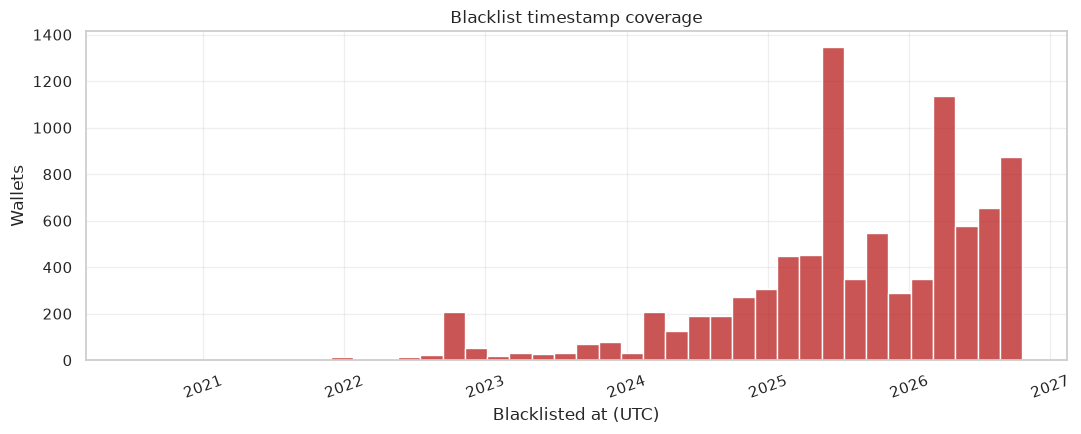

Timestamp coverage: 78.3%; range: 2020-06-26 15:22:39+00:00 -> 2026-10-20 01:18:12+00:00


In [37]:
blacklist_times = pd.to_datetime(
    suspicious_blacklisted_data["blacklisted_timestamp"], unit="s", utc=True, errors="coerce"
)
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.histplot(blacklist_times.dropna(), bins=40, color=COHORT_COLORS[COHORT_BLACKLISTED], ax=ax)
ax.set_title("Blacklist timestamp coverage")
ax.set_xlabel("Blacklisted at (UTC)")
ax.set_ylabel("Wallets")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
print(f"Timestamp coverage: {blacklist_times.notna().mean():.1%}; "
      f"range: {blacklist_times.min()} -> {blacklist_times.max()}")

### 3.3. Seed inventory

In [38]:
seed_rows = suspicious_wallet_hops_data.loc[
    suspicious_wallet_hops_data["hop_level"] == 0
]
seed_addresses = set(seed_rows["wallet_address"].dropna())
blacklisted_addresses = set(suspicious_blacklisted_data["wallet_address"].dropna())
print(f"Seed wallets (hop_level 0): {len(seed_addresses):,}")
print(f"Blacklisted wallets:        {len(blacklisted_addresses):,}")
print(f"Seeds that are blacklisted: {len(seed_addresses & blacklisted_addresses):,}")
print(f"Seeds not in the blacklist: {len(seed_addresses - blacklisted_addresses):,}")

Seed wallets (hop_level 0): 478
Blacklisted wallets:        11,418
Seeds that are blacklisted: 478
Seeds not in the blacklist: 0


### 3.4. Hop topology

In [39]:
hop_profile = (
    suspicious_wallet_hops_data
    .groupby("hop_level")
    .agg(
        rows=("wallet_address", "size"),
        unique_wallets=("wallet_address", "nunique"),
        unique_seeds=("seed_address", "nunique"),
    )
    .reset_index()
)
hop_profile["wallet_share"] = hop_profile["unique_wallets"] / hop_profile["unique_wallets"].sum()
display(hop_profile.style.format({"rows": "{:,}", "unique_wallets": "{:,}", "unique_seeds": "{:,}", "wallet_share": "{:.1%}"}))

print("Direction values:")
print(suspicious_wallet_hops_data["direction"].value_counts(dropna=False).to_string())

,hop_level,rows,unique_wallets,unique_seeds,wallet_share
0,0,478,478,478,0.0%
1,1,"321,544","280,833","4,251",17.7%
2,2,"339,121","300,712","1,958",19.0%
3,3,"372,040","335,620",302,21.2%
4,4,"351,235","332,452",124,21.0%
5,5,"352,133","335,049",107,21.1%


Direction values:
direction
BACKWARD    925394
FORWARD     811157


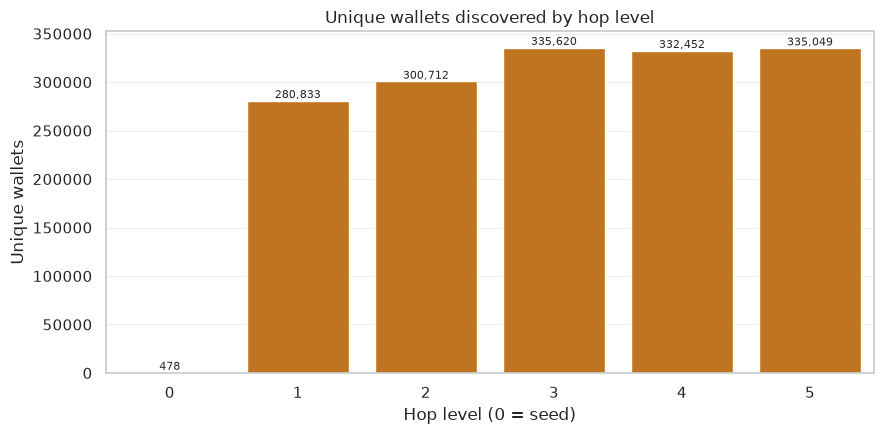

In [40]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(
    data=hop_profile,
    x="hop_level",
    y="unique_wallets",
    color=COHORT_COLORS[COHORT_SEED_ADJACENT],
    ax=ax,
)
ax.set_title("Unique wallets discovered by hop level")
ax.set_xlabel("Hop level (0 = seed)")
ax.set_ylabel("Unique wallets")
for patch, value in zip(ax.patches, hop_profile["unique_wallets"]):
    ax.text(
        patch.get_x() + patch.get_width() / 2,
        patch.get_height(),
        f"{value:,}",
        ha="center",
        va="bottom",
        fontsize=8,
    )
plt.tight_layout()
plt.show()

### 3.5. Seed-adjacent depth sensitivity

In [41]:
depth_table = (
    suspicious_wallet_hops_data
    .dropna(subset=["wallet_address"])
    .groupby("wallet_address")
    .agg(hop_level_min=("hop_level", "min"))
    .reset_index()
)
depth_table["hop_band"] = pd.cut(
    depth_table["hop_level_min"],
    bins=HOP_BIN_EDGES,
    labels=HOP_BIN_LABELS,
    include_lowest=True,
)
depth_summary = (
    depth_table.groupby("hop_band", observed=True)
    .size()
    .rename("wallets")
    .to_frame()
)
depth_summary["share"] = depth_summary["wallets"] / depth_summary["wallets"].sum()
display(depth_summary.style.format({"wallets": "{:,}", "share": "{:.1%}"}))
print("Hop 0 is the seed itself and is not part of the seed-adjacent cohort.")

,wallets,share
hop_band,,
hop 0,478,0.0%
hop 1,"280,750",20.9%
hop 2,"280,264",20.9%
hop 3,"285,398",21.3%
hop 4,"257,190",19.2%
hop 5,"238,641",17.8%


Hop 0 is the seed itself and is not part of the seed-adjacent cohort.


## 4. Cohort construction

### 4.1. Universe definition

The universe is defined **before** the feature tables are built. This avoids
the circularity in the old notebook, where cohort membership depended on which
H2/H4/H6 features happened to exist.

Universe = wallets in `transactions.from_address` ∪ `transactions.to_address`
∪ `accounts.address`.

In [42]:
transaction_wallets = pd.Index(
    pd.concat([
        suspicious_transactions_data["from_address"],
        suspicious_transactions_data["to_address"],
    ]).dropna().unique()
)
account_wallets = pd.Index(suspicious_account_data["address"].dropna().unique())
hop_wallets = pd.Index(suspicious_wallet_hops_data["wallet_address"].dropna().unique())
blacklist_wallets = pd.Index(suspicious_blacklisted_data["wallet_address"].dropna().unique())
wallet_universe = (
    transaction_wallets
    .union(account_wallets)
    .union(hop_wallets)
    .union(blacklist_wallets)
)

print(f"Transaction wallets: {len(transaction_wallets):,}")
print(f"Account wallets:     {len(account_wallets):,}")
print(f"Hop wallets:         {len(hop_wallets):,}")
print(f"Blacklisted wallets: {len(blacklist_wallets):,}")
print(f"Analysis universe:   {len(wallet_universe):,}")

Transaction wallets: 2,118,107
Account wallets:     2,125,343
Hop wallets:         1,342,721
Blacklisted wallets: 11,418
Analysis universe:   2,125,343


### 4.2. Cohort derivation

1. **Blacklisted** is a direct membership label. Deduplicate to one row per
   wallet.
2. **Seed-adjacent** comes from `wallet_hops`. A wallet can appear at several
   hop levels across seeds, so aggregate to `min(hop_level)`. Exclude
   `hop_level = 0` (the seed itself) and exclude blacklisted wallets by
   priority.
3. **Background** is the complement inside the universe.

The priority rule is enforced once here, not in every downstream plot.

In [43]:
blacklisted_wallets = (
    suspicious_blacklisted_data[
        ["wallet_address", "source_name", "label", "blacklisted_timestamp"]
    ]
    .drop_duplicates(subset=["wallet_address"])
    .copy()
)
blacklisted_wallets["is_blacklisted"] = True

hops_wallet = (
    suspicious_wallet_hops_data[
        ["wallet_address", "seed_address", "hop_level", "direction"]
    ]
    .dropna(subset=["wallet_address"])
    .groupby("wallet_address", as_index=False)
    .agg(
        hop_level_min=("hop_level", "min"),
        hop_levels=("hop_level", lambda values: tuple(sorted(set(values)))),
        seed_addresses=("seed_address", lambda values: tuple(sorted(set(values.dropna())))),
        n_hop_rows=("hop_level", "size"),
    )
)
hops_wallet["is_seed"] = hops_wallet["hop_level_min"].eq(0)

cohort_wallet_table = pd.DataFrame({"wallet_address": wallet_universe})
cohort_wallet_table = cohort_wallet_table.merge(
    blacklisted_wallets[
        ["wallet_address", "source_name", "label", "blacklisted_timestamp", "is_blacklisted"]
    ],
    on="wallet_address",
    how="left",
)
cohort_wallet_table["is_blacklisted"] = (
    cohort_wallet_table["is_blacklisted"].fillna(False).astype(bool)
)
cohort_wallet_table = cohort_wallet_table.merge(
    hops_wallet, on="wallet_address", how="left"
)
cohort_wallet_table["hop_level_min"] = cohort_wallet_table["hop_level_min"].astype("Int64")
cohort_wallet_table["is_seed"] = cohort_wallet_table["is_seed"].fillna(False).astype(bool)
cohort_wallet_table["is_seed_adjacent"] = (
    cohort_wallet_table["hop_level_min"].ge(1).fillna(False)
    & ~cohort_wallet_table["is_blacklisted"]
)
cohort_wallet_table["cohort"] = np.select(
    [
        cohort_wallet_table["is_blacklisted"],
        cohort_wallet_table["is_seed_adjacent"],
    ],
    [COHORT_BLACKLISTED, COHORT_SEED_ADJACENT],
    default=COHORT_BACKGROUND,
)
cohort_wallet_table["hop_band"] = pd.cut(
    cohort_wallet_table["hop_level_min"].astype("Float64"),
    bins=HOP_BIN_EDGES,
    labels=HOP_BIN_LABELS,
    include_lowest=True,
)

print(cohort_wallet_table["cohort"].value_counts().reindex(COHORT_ORDER).to_string())

cohort
blacklisted        11418
seed_adjacent    1338468
background        775457


### 4.3. Cohort sizes and weights

In [44]:
cohort_counts = (
    cohort_wallet_table["cohort"]
    .value_counts()
    .reindex(COHORT_ORDER)
    .fillna(0)
    .astype(int)
    .rename("wallets")
)
cohort_weights = (cohort_counts / cohort_counts.sum()).rename("share")
cohort_summary = pd.concat([cohort_counts, cohort_weights], axis=1)
cohort_summary["label"] = cohort_summary.index.map(COHORT_LABELS)
display(cohort_summary.style.format({"wallets": "{:,}", "share": "{:.2%}"}))

,wallets,share,label
cohort,,,
blacklisted,"11,418",0.54%,Blacklisted (labelled illicit)
seed_adjacent,"1,338,468",62.98%,Seed-adjacent (traversal)
background,"775,457",36.49%,"Background (unlabelled, in-dataset)"


### 4.4. Hop-level composition of the seed-adjacent cohort

In [45]:
seed_adjacent_hop = (
    cohort_wallet_table.loc[
        cohort_wallet_table["cohort"] == COHORT_SEED_ADJACENT
    ]
    .groupby("hop_level_min", observed=True)
    .size()
    .rename("wallets")
    .to_frame()
)
seed_adjacent_hop["share"] = seed_adjacent_hop["wallets"] / seed_adjacent_hop["wallets"].sum()
display(seed_adjacent_hop.style.format({"wallets": "{:,}", "share": "{:.1%}"}))

,wallets,share
hop_level_min,,
1,"278,469",20.8%
2,"279,048",20.8%
3,"285,273",21.3%
4,"257,111",19.2%
5,"238,567",17.8%


### 4.5. Persist the cohort table

In [46]:
cohort_export = cohort_wallet_table[[
    "wallet_address", "cohort", "hop_level_min", "hop_band",
    "is_blacklisted", "is_seed_adjacent", "is_seed", "n_hop_rows",
    "source_name", "label", "blacklisted_timestamp",
]]
cohort_path = EDA_OUTPUT / "cohorts.csv"
cohort_export.to_csv(cohort_path, index=False)
print(f"Saved cohort table ({len(cohort_export):,} wallets) to {cohort_path}")

Saved cohort table (2,125,343 wallets) to /home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/EDA_ILLICIT/cohorts.csv


## 5. Derived feature definitions

This section defines the wallet-level features **once**. No plots here: the
evidence sections below read `wallet_analysis_table` and never rebuild a
feature.

### 5.1. Wallet event tables

In [47]:
# 5.1.1 Parse only the columns needed by H2/H4/H6
accounts_analysis = suspicious_account_data.copy()
transactions_analysis = suspicious_transactions_data.copy()

accounts_analysis["first_seen_ts"] = pd.to_datetime(
    accounts_analysis["first_seen_timestamp"], utc=True, errors="coerce"
)
accounts_analysis["last_seen_ts"] = pd.to_datetime(
    accounts_analysis["last_seen_timestamp"], utc=True, errors="coerce"
)
accounts_analysis["account_lifetime_days"] = (
    accounts_analysis["last_seen_ts"] - accounts_analysis["first_seen_ts"]
).dt.total_seconds() / SECONDS_PER_DAY

transactions_analysis["block_ts"] = pd.to_datetime(
    transactions_analysis["block_timestamp"], utc=True, errors="coerce"
)


def build_wallet_events(transactions_df, value_columns=("amount",)):
    """One row per (transaction, wallet) with the wallet on either side.

    ``block_number`` is carried through so events that share a timestamp still
    have a deterministic order. H6 depends on that ordering when it computes
    inter-arrival times.
    """
    base_columns = ["tx_hash", "block_number", "block_ts", *value_columns]
    outgoing = transactions_df[base_columns + ["from_address"]].copy()
    outgoing = outgoing.rename(columns={"from_address": "wallet_address"})

    incoming = transactions_df[base_columns + ["to_address"]].copy()
    incoming = incoming.rename(columns={"to_address": "wallet_address"})

    events = pd.concat([outgoing, incoming], ignore_index=True)
    events = events.drop_duplicates(subset=["tx_hash", "wallet_address"])
    events = events.sort_values(
        ["wallet_address", "block_ts", "block_number"],
        kind="mergesort",
    ).reset_index(drop=True)
    return events


# 5.1.2 Build the two event tables once
wallet_events_usdt = build_wallet_events(
    transactions_analysis.loc[transactions_analysis["token_symbol"] == "USDT"], ("amount",)
)
wallet_events_all = build_wallet_events(transactions_analysis, ())

print(f"wallet_events_usdt: {wallet_events_usdt.shape[0]:,} rows")
print(f"wallet_events_all:  {wallet_events_all.shape[0]:,} rows")

wallet_events_usdt: 4,784,469 rows
wallet_events_all:  10,047,257 rows


In [48]:
# 5.1.3 Token symbol / contract consistency check
usdt_rows = transactions_analysis["token_symbol"] == "USDT"
usdt_contract_mismatch = transactions_analysis.loc[
    usdt_rows & (transactions_analysis["contract_address"] != USDT_CONTRACT_ADDRESS)
]
print(f"USDT rows: {usdt_rows.sum():,}")
print(f"USDT rows with a different contract: {len(usdt_contract_mismatch):,}")
print(f"USDT rows with a null contract: {transactions_analysis.loc[usdt_rows, 'contract_address'].isna().sum():,}")

USDT rows: 2,392,386
USDT rows with a different contract: 0
USDT rows with a null contract: 0


### 5.2. H2 — Temporal Burstiness features

In [49]:
# 5.2.1 H2 wallet-level features
def add_rolling_window_features(events_df, window_seconds=SECONDS_PER_HOUR):
    """Total volume and maximum sliding-window volume per wallet."""
    addresses = events_df["wallet_address"].to_numpy()
    timestamps = events_df["block_ts"].astype("int64").to_numpy() // NANOS_PER_SECOND
    amounts = events_df["amount"].to_numpy(dtype=float)

    starts = np.r_[0, np.flatnonzero(addresses[1:] != addresses[:-1]) + 1]
    ends = np.r_[starts[1:], len(addresses)]

    max_window = np.empty(len(starts), dtype=float)
    total = np.empty(len(starts), dtype=float)
    event_count = np.empty(len(starts), dtype=int)

    for k in range(len(starts)):
        start, end = starts[k], ends[k]
        group_ts = timestamps[start:end]
        group_amount = amounts[start:end]
        best = current = 0.0
        left = 0
        for right in range(len(group_ts)):
            current += group_amount[right]
            while group_ts[right] - group_ts[left] >= window_seconds:
                current -= group_amount[left]
                left += 1
            if current > best:
                best = current
        max_window[k] = best
        total[k] = group_amount.sum()
        event_count[k] = len(group_ts)

    features = pd.DataFrame({
        "wallet_address": addresses[starts],
        "usdt_event_count": event_count,
        "total_volume_usdt": total,
        "max_1h_volume_usdt": max_window,
    })
    features["burst_ratio"] = np.where(
        features["total_volume_usdt"] > 0,
        features["max_1h_volume_usdt"] / features["total_volume_usdt"],
        0.0,
    )
    return features


h2_wallet_features = add_rolling_window_features(wallet_events_usdt)

# Lifetime across all transactions gives full wallet coverage
wallet_lifetime = (
    wallet_events_all.groupby("wallet_address")["block_ts"]
    .agg(tx_first_seen_ts="min", tx_last_seen_ts="max", all_event_count="count")
    .reset_index()
)
wallet_lifetime["tx_lifetime_days"] = (
    wallet_lifetime["tx_last_seen_ts"] - wallet_lifetime["tx_first_seen_ts"]
).dt.total_seconds() / SECONDS_PER_DAY

h2_wallet_features = h2_wallet_features.merge(
    wallet_lifetime[["wallet_address", "tx_lifetime_days", "all_event_count"]],
    on="wallet_address", how="left",
)
h2_wallet_features = h2_wallet_features.merge(
    accounts_analysis[["address", "account_lifetime_days"]].rename(columns={"address": "wallet_address"}),
    on="wallet_address", how="left",
)

h2_wallet_features["lifetime_bucket"] = pd.cut(
    h2_wallet_features["tx_lifetime_days"],
    bins=LIFETIME_BIN_EDGES_DAYS,
    labels=LIFETIME_BIN_LABELS,
    right=True, include_lowest=True,
)
h2_wallet_features["usdt_event_count_bucket"] = pd.cut(
    h2_wallet_features["usdt_event_count"],
    bins=EVENT_COUNT_BIN_EDGES,
    labels=EVENT_COUNT_BIN_LABELS,
    right=True,
)

lifetime_ok = h2_wallet_features["tx_lifetime_days"] <= H2_LIFETIME_DAYS_MAX
burst_ok = h2_wallet_features["burst_ratio"] >= H2_BURST_RATIO_MIN
active_ok = h2_wallet_features["usdt_event_count"] >= H2_MIN_USDT_EVENTS

print(f"H2 wallets analysed: {len(h2_wallet_features):,}")
print(f"Account-lifetime coverage: {h2_wallet_features['account_lifetime_days'].notna().mean():.2%}")
print(f"Lifetime <= {H2_LIFETIME_DAYS_MAX:g} days: {lifetime_ok.mean():.1%}")
print(f"Burst ratio >= {H2_BURST_RATIO_MIN:.0%}: {burst_ok.mean():.1%}")
print(f"Pass both: {(lifetime_ok & burst_ok).mean():.1%}")
print(f"Pass both with activity floor: {(lifetime_ok & burst_ok & active_ok).mean():.1%}")

H2 wallets analysed: 731,508
Account-lifetime coverage: 0.25%
Lifetime <= 7 days: 69.8%
Burst ratio >= 75%: 92.9%
Pass both: 68.6%
Pass both with activity floor: 2.1%


### 5.3. H4 — TRX gas co-occurrence features

In [50]:
# 5.3.1 H4 wallet-level features
wallet_trx_funders = (
    transactions_analysis.loc[transactions_analysis["token_symbol"] == "TRX", ["to_address", "from_address"]]
    .drop_duplicates()
    .rename(columns={"to_address": "wallet_address", "from_address": "counterparty_address"})
)
wallet_usdt_recipients = (
    transactions_analysis.loc[transactions_analysis["token_symbol"] == "USDT", ["from_address", "to_address"]]
    .drop_duplicates()
    .rename(columns={"from_address": "wallet_address", "to_address": "counterparty_address"})
)

trx_funder_count = wallet_trx_funders.groupby("wallet_address").size().rename("trx_funder_count")
usdt_recipient_count = wallet_usdt_recipients.groupby("wallet_address").size().rename("usdt_recipient_count")
jaccard_intersection = (
    wallet_trx_funders.merge(wallet_usdt_recipients, on=["wallet_address", "counterparty_address"], how="inner")
    .groupby("wallet_address").size().rename("jaccard_intersection")
)

wallet_universe = trx_funder_count.index.union(usdt_recipient_count.index)
h4_wallet_features = pd.DataFrame({"wallet_address": wallet_universe})
h4_wallet_features["trx_funder_count"] = trx_funder_count.reindex(wallet_universe).fillna(0).astype(int).values
h4_wallet_features["usdt_recipient_count"] = usdt_recipient_count.reindex(wallet_universe).fillna(0).astype(int).values
h4_wallet_features["jaccard_intersection"] = jaccard_intersection.reindex(wallet_universe).fillna(0).astype(int).values
h4_wallet_features["jaccard_index"] = (
    h4_wallet_features["jaccard_intersection"]
    / (
        h4_wallet_features["trx_funder_count"]
        + h4_wallet_features["usdt_recipient_count"]
        - h4_wallet_features["jaccard_intersection"]
    )
)
h4_wallet_features["jaccard_index"] = h4_wallet_features["jaccard_index"].replace([np.inf, np.nan], 0.0)
h4_wallet_features["funding_pattern"] = np.select(
    [
        (h4_wallet_features["trx_funder_count"] > 0) & (h4_wallet_features["usdt_recipient_count"] > 0),
        (h4_wallet_features["trx_funder_count"] > 0),
        (h4_wallet_features["usdt_recipient_count"] > 0),
    ],
    ["Both", "TRX funder only", "USDT recipient only"],
    default="Neither",
)

h4_both_count = int(h4_wallet_features["funding_pattern"].eq("Both").sum())
h4_jaccard_pass = int((h4_wallet_features["jaccard_index"] >= H4_JACCARD_INDEX_MIN).sum())

print(f"H4 wallets analysed: {len(h4_wallet_features):,}")
print(f"Wallets with both sets non-empty: {h4_both_count:,}")
print(f"Wallets with Jaccard >= {H4_JACCARD_INDEX_MIN:.2f}: {h4_jaccard_pass:,}")

H4 wallets analysed: 1,050,421
Wallets with both sets non-empty: 84,609
Wallets with Jaccard >= 0.50: 3,494


### 5.4. H6 — Interval consistency features

In [ ]:
# 5.4.1 H6 wallet-level features
wallet_events_all["inter_arrival_seconds"] = (
    wallet_events_all.groupby("wallet_address", sort=False)["block_ts"]
    .diff().dt.total_seconds()
)

interval_stats = (
    wallet_events_all.dropna(subset=["inter_arrival_seconds"])
    .groupby("wallet_address")["inter_arrival_seconds"]
    .agg(delta_count="count", mean_delta_seconds="mean", std_delta_seconds="std")
    .reset_index()
)
interval_stats["cv_delta_t"] = np.where(
    interval_stats["mean_delta_seconds"] > 0,
    interval_stats["std_delta_seconds"] / interval_stats["mean_delta_seconds"],
    np.nan,
)
interval_stats["mean_delta_minutes"] = interval_stats["mean_delta_seconds"] / SECONDS_PER_MINUTE

wallet_event_counts = wallet_events_all.groupby("wallet_address").size().rename("event_count")
h6_wallet_features = (
    wallet_event_counts.to_frame().reset_index()
    .merge(interval_stats, on="wallet_address", how="left")
)
h6_wallet_features["event_count_bucket"] = pd.cut(
    h6_wallet_features["event_count"],
    bins=EVENT_COUNT_BIN_EDGES,
    labels=EVENT_COUNT_BIN_LABELS,
    right=True,
)

h6_event_ok = h6_wallet_features["event_count"] >= H6_EVENT_COUNT_MIN
h6_cv_ok = h6_wallet_features["cv_delta_t"] < H6_CV_DELTA_T_MAX

print(f"H6 wallets with at least one event: {len(h6_wallet_features):,}")
print(f"Wallets with a defined CV: {h6_wallet_features['cv_delta_t'].notna().sum():,}")
print(f"Wallets with N >= {H6_EVENT_COUNT_MIN}: {h6_event_ok.sum():,}")
print(f"Pass N >= {H6_EVENT_COUNT_MIN} and CV < {H6_CV_DELTA_T_MAX}: {(h6_event_ok & h6_cv_ok).sum():,}")

### 5.5. Master wallet table and rule flags

The master table is one row per wallet in the analysis universe. It joins the
cohort assignment to the H2/H4/H6 features and adds the rule flags used by the
evidence sections.

In [ ]:
wallet_analysis_table = (
    cohort_wallet_table
    .merge(
        h2_wallet_features[[
            "wallet_address", "tx_lifetime_days", "burst_ratio",
            "usdt_event_count", "total_volume_usdt", "max_1h_volume_usdt",
            "account_lifetime_days",
        ]],
        on="wallet_address",
        how="left",
    )
    .merge(
        h4_wallet_features[[
            "wallet_address", "jaccard_index", "trx_funder_count",
            "usdt_recipient_count", "funding_pattern",
        ]],
        on="wallet_address",
        how="left",
    )
    .merge(
        h6_wallet_features[[
            "wallet_address", "event_count", "cv_delta_t", "mean_delta_minutes",
        ]],
        on="wallet_address",
        how="left",
    )
)

wallet_analysis_table["h2_pass"] = (
    (wallet_analysis_table["tx_lifetime_days"] <= H2_LIFETIME_DAYS_MAX)
    & (wallet_analysis_table["burst_ratio"] >= H2_BURST_RATIO_MIN)
)
wallet_analysis_table["h2_pass_with_activity_floor"] = (
    wallet_analysis_table["h2_pass"]
    & (wallet_analysis_table["usdt_event_count"] >= H2_MIN_USDT_EVENTS)
)
wallet_analysis_table["h4_eligible"] = (
    wallet_analysis_table["funding_pattern"].eq("Both")
)
wallet_analysis_table["h4_pass"] = (
    wallet_analysis_table["jaccard_index"] >= H4_JACCARD_INDEX_MIN
)
wallet_analysis_table["h6_eligible"] = (
    wallet_analysis_table["cv_delta_t"].notna()
    & (wallet_analysis_table["event_count"] >= H6_EVENT_COUNT_MIN)
)
wallet_analysis_table["h6_pass"] = (
    (wallet_analysis_table["event_count"] >= H6_EVENT_COUNT_MIN)
    & (wallet_analysis_table["cv_delta_t"] < H6_CV_DELTA_T_MAX)
)

print(f"Master table: {wallet_analysis_table.shape[0]:,} wallets x {wallet_analysis_table.shape[1]} columns")
display(wallet_analysis_table.groupby("cohort").size().reindex(COHORT_ORDER).to_frame("wallets"))

### 5.6. Feature coverage matrix

A metric is only comparable across cohorts when the denominator is explicit.
This table reports how many wallets in each cohort actually have a defined
value for each metric.

In [ ]:
FEATURE_COLUMNS = [
    "tx_lifetime_days", "burst_ratio", "total_volume_usdt", "max_1h_volume_usdt",
    "usdt_event_count", "jaccard_index", "event_count", "cv_delta_t",
    "mean_delta_minutes",
]
coverage_counts = (
    wallet_analysis_table.groupby("cohort")[FEATURE_COLUMNS]
    .agg(lambda series: int(series.notna().sum()))
    .reindex(COHORT_ORDER)
)
coverage_share = coverage_counts.div(cohort_counts, axis=0)
display(coverage_counts.style.format("{:,}"))
display(coverage_share.style.format("{:.1%}"))

coverage_path = EDA_OUTPUT / "feature_coverage.csv"
coverage_counts.to_csv(coverage_path)
print(f"Saved feature coverage to {coverage_path}")

### 5.7. Cohort weights per analysis universe

The all-wallet mix is not the same as the H2, H4, or H6 mix. This table
reports the cohort shares for each analysis universe. Those weights are the
`w_b`, `w_s`, and `w_n` in the pooled-rate decomposition.

In [ ]:
def cohort_weight_frame(frame, universe_name):
    """Count and share by cohort for one analysis universe."""
    counts = frame["cohort"].value_counts().reindex(COHORT_ORDER).fillna(0).astype(int)
    return pd.DataFrame({
        "universe": universe_name,
        "cohort": counts.index,
        "wallets": counts.values,
        "share": counts.values / max(counts.sum(), 1),
    })


analysis_universes = {
    "all wallets": wallet_analysis_table,
    "H2 active (USDT)": wallet_analysis_table.dropna(subset=["tx_lifetime_days"]),
    "H4 Both sets": wallet_analysis_table.loc[wallet_analysis_table["h4_eligible"]],
    "H6 CV defined": wallet_analysis_table.dropna(subset=["cv_delta_t"]),
    "H6 N>=5 & CV": wallet_analysis_table.loc[wallet_analysis_table["h6_eligible"]],
}
cohort_weights_by_universe = pd.concat(
    [cohort_weight_frame(frame, name) for name, frame in analysis_universes.items()],
    ignore_index=True,
)
display(
    cohort_weights_by_universe.pivot(
        index="universe", columns="cohort", values="share"
    ).reindex(columns=COHORT_ORDER).fillna(0).style.format("{:.2%}")
)

weights_path = EDA_OUTPUT / "cohort_weights.csv"
cohort_weights_by_universe.to_csv(weights_path, index=False)
print(f"Saved cohort weights to {weights_path}")

In [ ]:
weight_pivot = (
    cohort_weights_by_universe.pivot(index="universe", columns="cohort", values="share")
    .reindex(columns=COHORT_ORDER)
    .fillna(0)
)
fig, ax = plt.subplots(figsize=(10, 5))
weight_pivot.plot(
    kind="bar",
    stacked=True,
    color=[COHORT_COLORS[cohort] for cohort in COHORT_ORDER],
    ax=ax,
)
ax.set_title("Cohort share by analysis universe")
ax.set_xlabel("")
ax.set_ylabel("Share of wallets")
ax.legend(title="Cohort", labels=[COHORT_LABELS[c] for c in COHORT_ORDER], loc="upper right", fontsize=8)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## Part II — Evidence by plot type

Each section below is a **plot type**, not a hypothesis. A metric appears once
per plot type, and its four-view block keeps the combined, blacklisted,
seed-adjacent, and background panels side by side.

Read every block in this order:

1. **B vs D** — does the labelled cohort differ from the local background?
2. **C vs D** — does the traversal proxy move in the same direction?
3. **A** — only then ask how the mixture averages the three panels.

If A and B disagree, trust B for rule decisions. A is a weighted mixture, not
the target population.

## 6. Continuous distributions (histogram + KDE)

### 6.1. H2 — wallet lifetime (`tx_lifetime_days`)

**Definition.** `max(block_timestamp) - min(block_timestamp)` per wallet, in
days, across all transactions. Fully covered.

**Expected direction.** H2 assumes illicit wallets are short-lived, so the
blacklisted panel should sit to the left of the background panel.

**Threshold.** 7 days.

In [ ]:
four_view_histogram("tx_lifetime_days", wallet_analysis_table)

**Reading note.** Compare B with D first. If the blacklisted median is not
below the background median, the H2 lifetime premise is contradicted for this
sample. Panel A is the mixture and is dominated by whichever cohort has the
largest weight.

### 6.2. H2 — burst ratio (`burst_ratio`)

**Definition.** `max_1h_volume_usdt / total_volume_usdt`. A one-shot wallet has
`burst_ratio = 1.0` by construction, so this metric must be read with the
activity count in §6.5.

**Expected direction.** Illicit wallets should sit closer to 1.0.

**Threshold.** 0.75.

In [ ]:
four_view_histogram("burst_ratio", wallet_analysis_table)

**Reading note.** A spike at 1.0 is expected in every cohort because of
one-shot wallets. The informative comparison is the share below the 0.75 line,
not the height of the spike.

### 6.3. H2 — total USDT volume (`total_volume_usdt`)

**Definition.** Sum of USDT amount across the wallet's de-duplicated events.

**Expected direction.** Descriptive only; volume is heavy-tailed and is not a
standalone rule condition.

In [ ]:
four_view_histogram("total_volume_usdt", wallet_analysis_table)

**Reading note.** Read the tails, not the mean. A log10 view is required
because volume spans roughly ten orders of magnitude.

### 6.4. H2 — maximum 1-hour volume (`max_1h_volume_usdt`)

**Definition.** Largest USDT volume observed inside any sliding 1-hour window.

**Expected direction.** Descriptive only; it is the numerator of the burst
ratio.

In [ ]:
four_view_histogram("max_1h_volume_usdt", wallet_analysis_table)

**Reading note.** Compare this panel with §6.3. If the two distributions look
nearly identical, most wallets transact in a single burst and the ratio is
close to 1.0.

### 6.5. H2 — USDT activity count (`usdt_event_count`)

**Definition.** Number of de-duplicated USDT events in which the wallet is the
sender or receiver.

**Expected direction.** The activity floor `N >= 5` is a guard against the
trivial `burst_ratio = 1.0` case.

In [ ]:
four_view_histogram("usdt_event_count", wallet_analysis_table)

**Reading note.** The blacklisted cohort should have more activity than the
background if the rule is targeting operational wallets rather than one-shot
addresses. This panel sets the denominator for the H2 activity-floor version.

### 6.6. H4 — Jaccard index (`jaccard_index`)

**Definition.** `|TRX funders ∩ USDT recipients| / |TRX funders ∪ USDT recipients|`.
Set to 0 when either set is empty.

**Expected direction.** Illicit wallets should have a higher Jaccard index.

**Threshold.** 0.50.

In [ ]:
four_view_histogram("jaccard_index", wallet_analysis_table)

**Reading note.** The metric is zero-inflated and only defined for wallets with
both a TRX-funder set and a USDT-recipient set. Read §7.5 for the denominator
and §10.4 for the conditional pass rate on the `Both` subset. Do not compare
the raw pass rate over the full wallet universe.

### 6.7. H6 — event count (`event_count`)

**Definition.** Number of de-duplicated wallet events across all tokens.

**Expected direction.** H6 only applies when `N >= 5`.

**Threshold.** 5.

In [ ]:
four_view_histogram("event_count", wallet_analysis_table)

**Reading note.** The `N >= 5` line is the eligibility boundary. The CV is
undefined for wallets below it, so the H6 comparison must use the eligible
subset in §10.4.

### 6.8. H6 — coefficient of variation of inter-arrival times (`cv_delta_t`)

**Definition.** `std(inter-arrival seconds) / mean(inter-arrival seconds)`.
Undefined for fewer than three events or when all gaps are zero.

**Expected direction.** Bot-like wallets should have low CV, so the blacklisted
panel should sit to the left of the background panel.

**Threshold.** 0.15.

In [ ]:
four_view_histogram("cv_delta_t", wallet_analysis_table)

**Reading note.** The CV is undefined for most wallets. Compare the defined-CV
panels and report the denominator. A median far above 0.15 means the threshold
is deep in the tail.

### 6.9. H6 — mean inter-arrival time (`mean_delta_minutes`)

**Definition.** Mean gap between consecutive wallet events, in minutes.

**Expected direction.** Descriptive only; a fixed-interval bot can have either
a small or a large mean gap, so the CV is the discriminating statistic.

In [ ]:
four_view_histogram("mean_delta_minutes", wallet_analysis_table)

**Reading note.** Use this panel to separate "fast bot" from "slow bot". A low
CV with a large mean is still consistent with automation.

## 7. Binned and zero-inflated distributions (ordered bars)

Ordered bins make the threshold boundaries explicit and keep the zero mass
visible. These are still distribution views, but they use bars rather than
histograms because the underlying values are discrete or strongly zero-inflated.

### 7.1. H2 — wallet lifetime ranges

In [ ]:
four_view_binned("tx_lifetime_binned", wallet_analysis_table)

**Reading note.** The `<1h` bar is the one-shot mass and the `1-7d` bar is the
H2 pass zone for lifetime. Compare B and D before reading A.

### 7.2. H2 — USDT activity ranges

In [ ]:
four_view_binned("usdt_event_count_binned", wallet_analysis_table)

**Reading note.** `1` is the one-shot majority. `5-9`, `10-49`, and above are
the H2 activity-floor population.

### 7.3. H4 — distinct TRX funders

In [ ]:
four_view_binned("trx_funder_count_binned", wallet_analysis_table)

**Reading note.** The `0` bar is the structural bottleneck: a wallet with no
TRX funder cannot have a non-zero Jaccard index. Compare the zero share across
B, C, and D.

### 7.4. H4 — distinct USDT recipients

In [ ]:
four_view_binned("usdt_recipient_count_binned", wallet_analysis_table)

**Reading note.** The recipient side carries most of the H4 coverage. A high
blacklisted recipient count combined with a low TRX-funder count is the
expected failure mode of this rule.

### 7.5. H4 — Jaccard index ranges

In [ ]:
four_view_binned("jaccard_index_binned", wallet_analysis_table)

**Reading note.** The `J >= 0.5` bar is the rule pass zone. Because the metric
is defined only for the `Both` subset, pair this plot with the conditional
pass-rate table in §10.4.

### 7.6. H6 — event-count ranges

In [ ]:
four_view_binned("event_count_binned", wallet_analysis_table)

**Reading note.** The `1` and `2-4` bars are ineligible for H6. The rule is
evaluated only on `5-9` and above.

### 7.7. Zero-inflated detail (blacklisted only)

The two-panel view below separates the zero mass from the non-zero
distribution. It is shown for the blacklisted cohort only, because the
four-view block above already carries the cross-cohort comparison.

In [ ]:
def plot_zero_inflated_detail(series, *, title, xlabel, palette_name, band_edges,
                              band_labels, transform="log10", threshold=None,
                              threshold_label=None):
    """Two panels: ordered zero/non-zero bins (left) and non-zero values (right)."""
    palette = HYPOTHESIS_PALETTES[palette_name]["mono"]
    values = pd.Series(series).dropna().astype(float)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.4]})

    binned = pd.cut(
        values, bins=band_edges, labels=band_labels, right=True, include_lowest=True
    )
    counts = binned.value_counts().reindex(band_labels).fillna(0).astype(int)
    colors = monochromatic_sequence(
        {"H2": H2_HUE, "H4": H4_HUE, "H6": H6_HUE}[palette_name], len(band_labels)
    )
    bars = axes[0].bar(band_labels, counts.values, color=colors, edgecolor="white")
    total = counts.sum()
    for bar, count in zip(bars, counts.values):
        share = count / total * 100 if total else 0
        axes[0].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{count:,}\n({share:.1f}%)",
            ha="center",
            va="bottom",
            fontsize=8,
        )
    axes[0].set_title("Range bins")
    axes[0].set_xlabel(xlabel)
    axes[0].set_ylabel("Wallets")
    axes[0].tick_params(axis="x", rotation=15)
    axes[0].set_ylim(0, max(counts.values) * 1.20 if len(counts) else 1)

    positive = values[values > 0]
    if len(positive):
        plot_values = np.log10(positive) if transform == "log10" else positive
        sns.histplot(
            plot_values,
            bins=30,
            kde=(plot_values.nunique() > 1),
            color=palette["mid"],
            edgecolor="white",
            alpha=0.78,
            ax=axes[1],
        )
        axes[1].axvline(
            transform_value(positive.mean(), transform),
            color=palette["darkest"],
            linewidth=2.0,
            linestyle="-",
            label=f"Mean = {compact_number(positive.mean())}",
        )
        axes[1].axvline(
            transform_value(positive.median(), transform),
            color=palette["dark"],
            linewidth=2.0,
            linestyle="--",
            label=f"Median = {compact_number(positive.median())}",
        )
        if threshold is not None:
            axes[1].axvline(
                transform_value(threshold, transform),
                color=THRESHOLD_COLOR,
                linewidth=1.8,
                linestyle=":",
                label=threshold_label or f"Threshold = {threshold}",
            )
        if transform == "log10":
            axes[1].xaxis.set_major_formatter(
                FuncFormatter(lambda value, _: inverse_log_tick(value, "log10"))
            )
        axes[1].legend(loc="upper right", frameon=True, fontsize=8)
    else:
        empty_panel(axes[1], "No non-zero values")

    axes[1].set_title("Non-zero values")
    suffix = " (log10 scale)" if transform == "log10" else ""
    axes[1].set_xlabel(f"{xlabel}{suffix}")
    axes[1].set_ylabel("Frequency")
    zero_share = (values == 0).mean()
    axes[1].text(
        0.01,
        0.97,
        f"zero share = {zero_share:.2%}",
        transform=axes[1].transAxes,
        va="top",
        fontsize=8,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#D1D5DB", alpha=0.88),
    )

    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    plt.show()


blacklisted_table = cohort_subset(wallet_analysis_table, COHORT_BLACKLISTED)

In [ ]:
plot_zero_inflated_detail(
    blacklisted_table["trx_funder_count"],
    title="H4 | Blacklisted only — distinct TRX funders",
    xlabel="TRX funders",
    palette_name="H4",
    band_edges=TRX_FUNDER_BIN_EDGES,
    band_labels=TRX_FUNDER_BIN_LABELS,
)

In [ ]:
plot_zero_inflated_detail(
    blacklisted_table["usdt_recipient_count"],
    title="H4 | Blacklisted only — distinct USDT recipients",
    xlabel="USDT recipients",
    palette_name="H4",
    band_edges=TRX_FUNDER_BIN_EDGES,
    band_labels=TRX_FUNDER_BIN_LABELS,
)

In [ ]:
plot_zero_inflated_detail(
    blacklisted_table["jaccard_index"],
    title="H4 | Blacklisted only — Jaccard index",
    xlabel="Jaccard index",
    palette_name="H4",
    band_edges=JACCARD_BIN_EDGES,
    band_labels=JACCARD_BIN_LABELS,
    transform=None,
    threshold=H4_JACCARD_INDEX_MIN,
    threshold_label="0.50 threshold",
)

**Reading note.** The zero share is the dominant fact for H4. A rule that is
only defined on a small `Both` subset cannot be judged on the full-universe
pass rate.

## 8. Bivariate and threshold views (hexbin / quadrant)

These panels place two rule variables on the same axes. The threshold lines
divide the plane into pass and fail zones, so the visual density can be read as
a rule decision surface.

### 8.1. H2 — lifetime × burst ratio

In [ ]:
def four_view_hexbin_h2(table):
    """Panels A-D for the H2 threshold plane."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
    hb = None
    for ax, (title, cohort) in zip(axes.ravel(), COHORT_PANELS):
        subset = table if cohort is None else cohort_subset(table, cohort)
        subset = subset.dropna(subset=["tx_lifetime_days", "burst_ratio"])
        if subset.empty:
            empty_panel(ax)
            ax.set_title(title, fontsize=11)
            continue
        hb = ax.hexbin(
            subset["tx_lifetime_days"].clip(upper=LIFETIME_CLIP_DAYS),
            subset["burst_ratio"],
            gridsize=45,
            cmap=monochromatic_cmap(H2_HUE),
            norm=LogNorm(),
            mincnt=1,
        )
        ax.axvline(
            H2_LIFETIME_DAYS_MAX, color=THRESHOLD_COLOR, linestyle=":", linewidth=1.8,
            label="7 days",
        )
        ax.axhline(
            H2_BURST_RATIO_MIN, color=THRESHOLD_COLOR, linestyle=":", linewidth=1.8,
            label="75% burst",
        )
        ax.set_xlim(0, LIFETIME_CLIP_DAYS)
        ax.set_title(title, fontsize=11)
        ax.set_xlabel("Lifetime (days), clipped at 30")
        ax.set_ylabel("Burst ratio")
        if ax is axes[0, 0]:
            ax.legend(loc="lower left", fontsize=8)
    if hb is not None:
        fig.colorbar(hb, ax=axes.ravel().tolist(), label="Wallet density (log)", shrink=0.8)
    fig.suptitle("H2 | Threshold quadrant: lifetime vs burst ratio", fontsize=14)
    fig.tight_layout()
    plt.show()


four_view_hexbin_h2(wallet_analysis_table)

**Reading note.** The pass zone is the upper-left rectangle. Compare the mass
inside that rectangle for B and D. A dense pass zone in both cohorts means the
rule is not separating them.

### 8.2. H4 — TRX funders × USDT recipients

In [ ]:
def four_view_hexbin_h4(table):
    """Panels A-D for the H4 co-occurrence plane."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
    hb = None
    for ax, (title, cohort) in zip(axes.ravel(), COHORT_PANELS):
        subset = table if cohort is None else cohort_subset(table, cohort)
        subset = subset.dropna(subset=["trx_funder_count", "usdt_recipient_count"])
        if subset.empty:
            empty_panel(ax)
            ax.set_title(title, fontsize=11)
            continue
        hb = ax.hexbin(
            np.log1p(subset["trx_funder_count"]),
            np.log1p(subset["usdt_recipient_count"]),
            gridsize=45,
            cmap=monochromatic_cmap(H4_HUE),
            norm=LogNorm(),
            mincnt=1,
        )
        ax.set_title(title, fontsize=11)
        ax.set_xlabel("TRX funders (log1p scale)")
        ax.set_ylabel("USDT recipients (log1p scale)")
        ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: compact_number(np.expm1(value))))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: compact_number(np.expm1(value))))
    if hb is not None:
        fig.colorbar(hb, ax=axes.ravel().tolist(), label="Wallet density (log)", shrink=0.8)
    fig.suptitle("H4 | Co-occurrence density: TRX funders vs USDT recipients", fontsize=14)
    fig.tight_layout()
    plt.show()


four_view_hexbin_h4(wallet_analysis_table)

**Reading note.** Most wallets sit on the zero axes. The both-set population is
the only place where Jaccard is defined. Use the blacklisted-only detail below
to see the Jaccard colouring inside that subset.

In [ ]:
h4_both_detail = (
    cohort_subset(wallet_analysis_table, COHORT_BLACKLISTED)
    .loc[lambda frame: frame["funding_pattern"].eq("Both")]
)
if h4_both_detail.empty:
    print("No blacklisted wallets have both sets non-empty in this snapshot.")
else:
    fig, ax = plt.subplots(figsize=(9, 6))
    scatter = ax.scatter(
        h4_both_detail["trx_funder_count"],
        h4_both_detail["usdt_recipient_count"],
        c=h4_both_detail["jaccard_index"],
        cmap=monochromatic_cmap(H4_HUE),
        s=32,
        alpha=0.85,
        edgecolor="white",
        linewidth=0.3,
    )
    passing = h4_both_detail[h4_both_detail["jaccard_index"] >= H4_JACCARD_INDEX_MIN]
    ax.scatter(
        passing["trx_funder_count"],
        passing["usdt_recipient_count"],
        s=60,
        facecolor="none",
        edgecolor=HYPOTHESIS_PALETTES["H4"]["complement"],
        linewidth=1.4,
        label=f"J >= 0.50 (n={len(passing):,})",
    )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("TRX funders (log scale)")
    ax.set_ylabel("USDT recipients (log scale)")
    ax.set_title("H4 | Blacklisted only — both-set wallets")
    ax.legend(loc="lower right", fontsize=8)
    fig.colorbar(scatter, ax=ax, label="Jaccard index")
    plt.tight_layout()
    plt.show()

### 8.3. H6 — event count × CV

In [ ]:
def four_view_hexbin_h6(table):
    """Panels A-D for the H6 threshold plane."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
    hb = None
    for ax, (title, cohort) in zip(axes.ravel(), COHORT_PANELS):
        subset = table if cohort is None else cohort_subset(table, cohort)
        subset = subset.dropna(subset=["event_count", "cv_delta_t"])
        if subset.empty:
            empty_panel(ax)
            ax.set_title(title, fontsize=11)
            continue
        hb = ax.hexbin(
            np.log10(subset["event_count"]),
            subset["cv_delta_t"],
            gridsize=45,
            cmap=monochromatic_cmap(H6_HUE),
            norm=LogNorm(),
            mincnt=1,
        )
        ax.set_ylim(0, CV_PLOT_CLIP)
        ax.axvline(
            np.log10(H6_EVENT_COUNT_MIN), color=THRESHOLD_COLOR, linestyle=":", linewidth=1.8,
            label=f"N = {H6_EVENT_COUNT_MIN}",
        )
        ax.axhline(
            H6_CV_DELTA_T_MAX, color=THRESHOLD_COLOR, linestyle=":", linewidth=1.8,
            label=f"CV = {H6_CV_DELTA_T_MAX}",
        )
        ax.set_title(title, fontsize=11)
        ax.set_xlabel("Events per wallet (log scale)")
        ax.set_ylabel(f"CV(delta t), clipped at {CV_PLOT_CLIP}")
        ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: compact_number(10 ** value)))
        if ax is axes[0, 0]:
            ax.legend(loc="upper right", fontsize=8)
    if hb is not None:
        fig.colorbar(hb, ax=axes.ravel().tolist(), label="Wallet density (log)", shrink=0.8)
    fig.suptitle("H6 | Threshold quadrant: activity vs interval consistency", fontsize=14)
    fig.tight_layout()
    plt.show()


four_view_hexbin_h6(wallet_analysis_table)

**Reading note.** The H6 pass zone is the right-lower corner: enough events and
low CV. A blacklisted panel with almost no mass there means the rule has low
recall on labelled illicit wallets.

## 9. Categorical and composition views

Categorical plots answer composition questions: who the cohorts are and what
they are made of. They are not distributions of a continuous rule variable.

### 9.1. Cohort composition

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(
    x=cohort_summary.index,
    y=cohort_summary["wallets"],
    hue=cohort_summary.index,
    palette=COHORT_COLORS,
    legend=False,
    ax=ax,
)
ax.set_title("Wallet count by cohort")
ax.set_xlabel("")
ax.set_ylabel("Wallets")
for patch, value, share in zip(
    ax.patches, cohort_summary["wallets"], cohort_summary["share"]
):
    ax.text(
        patch.get_x() + patch.get_width() / 2,
        patch.get_height(),
        f"{value:,}\n({share:.1%})",
        ha="center",
        va="bottom",
        fontsize=8,
    )
plt.tight_layout()
plt.show()

### 9.2. H4 — funding pattern by cohort

In [ ]:
pattern_order = ["Both", "TRX funder only", "USDT recipient only", "Neither"]
pattern_counts = (
    pd.crosstab(wallet_analysis_table["cohort"], wallet_analysis_table["funding_pattern"])
    .reindex(index=COHORT_ORDER, columns=pattern_order)
    .fillna(0)
    .astype(int)
)
pattern_share = pattern_counts.div(pattern_counts.sum(axis=1), axis=0)
display(pattern_counts)
display(pattern_share.style.format("{:.1%}"))

fig, ax = plt.subplots(figsize=(11, 5))
pattern_share.plot(
    kind="bar",
    stacked=True,
    color=[HYPOTHESIS_PALETTES["H4"]["pattern"][name] for name in pattern_order],
    ax=ax,
)
ax.set_title("H4 funding pattern share by cohort")
ax.set_xlabel("")
ax.set_ylabel("Share of wallets")
ax.legend(title="Pattern", loc="upper right", fontsize=8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 9.3. Token composition

In [ ]:
token_counts = transactions_analysis["token_symbol"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(
    token_counts.index.astype(str),
    token_counts.values,
    color=[HYPOTHESIS_PALETTES["H4"]["token"].get(name, "#9CA3AF") for name in token_counts.index],
    edgecolor="white",
)
total = token_counts.sum()
for bar, count in zip(bars, token_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({count / total:.1%})",
        ha="center",
        va="bottom",
        fontsize=8,
    )
ax.set_title("Transfer count by token")
ax.set_xlabel("Token symbol")
ax.set_ylabel("Transactions")
ax.set_ylim(0, max(token_counts.values) * 1.20)
plt.tight_layout()
plt.show()

### 9.4. Blacklist source and label by cohort

In [ ]:
source_by_cohort = (
    cohort_wallet_table.loc[cohort_wallet_table["cohort"] == COHORT_BLACKLISTED]
    ["source_name"]
    .value_counts(dropna=False)
    .rename("wallets")
    .to_frame()
)
display(source_by_cohort)

label_by_cohort = (
    cohort_wallet_table.loc[cohort_wallet_table["cohort"] == COHORT_BLACKLISTED]
    ["label"]
    .value_counts(dropna=False)
    .rename("wallets")
    .to_frame()
)
display(label_by_cohort)

**Reading note.** The current blacklist is 100% TronScan with `label = 1`, so
this section is a provenance check rather than a stratification. It becomes
useful when additional label sources are ingested.

## 10. Cross-cohort statistics

This section moves from plots to tables. All comparisons are **blacklisted vs
background** and **seed-adjacent vs background**; the combined cohort is never
used as a control.

### 10.1. Quantile table per cohort

In [ ]:
COMPARISON_METRICS = {
    "tx_lifetime_days": "H2 lifetime (days)",
    "burst_ratio": "H2 burst ratio",
    "total_volume_usdt": "H2 total USDT volume",
    "jaccard_index": "H4 Jaccard index",
    "event_count": "H6 event count",
    "cv_delta_t": "H6 CV(inter-arrival)",
}
QUANTILE_PROBS = [0.10, 0.25, 0.50, 0.75, 0.90]

quantile_rows = []
for metric, metric_label in COMPARISON_METRICS.items():
    for cohort in COHORT_ORDER:
        values = (
            wallet_analysis_table.loc[wallet_analysis_table["cohort"] == cohort, metric]
            .dropna()
            .astype(float)
        )
        row = {
            "metric": metric,
            "metric_label": metric_label,
            "cohort": cohort,
            "n": len(values),
        }
        for probability in QUANTILE_PROBS:
            row[f"p{int(probability * 100)}"] = (
                values.quantile(probability) if len(values) else np.nan
            )
        quantile_rows.append(row)

quantile_table = pd.DataFrame(quantile_rows)
display(quantile_table.style.format({"n": "{:,}", "p10": "{:.3g}", "p25": "{:.3g}", "p50": "{:.3g}", "p75": "{:.3g}", "p90": "{:.3g}"}))
quantile_table.to_csv(EDA_OUTPUT / "cohort_quantiles.csv", index=False)

### 10.2. Box/violin small multiples

In [ ]:
BOX_METRICS = [
    "tx_lifetime_days",
    "burst_ratio",
    "total_volume_usdt",
    "jaccard_index",
    "event_count",
    "cv_delta_t",
]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, metric in zip(axes.ravel(), BOX_METRICS):
    sns.boxplot(
        data=wallet_analysis_table,
        x="cohort",
        y=metric,
        order=COHORT_ORDER,
        hue="cohort",
        palette=COHORT_COLORS,
        legend=False,
        showfliers=False,
        ax=ax,
    )
    ax.set_title(COMPARISON_METRICS.get(metric, metric))
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
    if metric in ("burst_ratio", "jaccard_index"):
        ax.set_ylim(-0.02, 1.02)
    if metric == "cv_delta_t":
        ax.set_ylim(0, CV_PLOT_CLIP)
    if metric == "tx_lifetime_days":
        ax.set_ylim(0, 90)
    if metric in ("total_volume_usdt", "event_count"):
        ax.set_yscale("log")
plt.suptitle("Distribution comparison by cohort (boxplots, outliers hidden)", fontsize=14)
plt.tight_layout()
plt.show()

### 10.3. Non-parametric tests and effect sizes

In [ ]:
def compare_metric(values_a, values_b):
    """Mann-Whitney U + KS + Cliff's delta for one metric and two cohorts."""
    values_a = pd.Series(values_a).dropna().astype(float)
    values_b = pd.Series(values_b).dropna().astype(float)
    if len(values_a) < MIN_GROUP_SIZE or len(values_b) < MIN_GROUP_SIZE:
        return {
            "n_a": len(values_a),
            "n_b": len(values_b),
            "median_a": np.nan,
            "median_b": np.nan,
            "mannwhitney_u": np.nan,
            "mannwhitney_p": np.nan,
            "ks_statistic": np.nan,
            "ks_p": np.nan,
            "cliffs_delta": np.nan,
        }
    u_stat, p_value = mannwhitneyu(values_a, values_b, alternative="two-sided")
    ks_stat, ks_p = ks_2samp(values_a, values_b)
    cliffs_delta = (2 * u_stat / (len(values_a) * len(values_b))) - 1
    return {
        "n_a": len(values_a),
        "n_b": len(values_b),
        "median_a": values_a.median(),
        "median_b": values_b.median(),
        "mannwhitney_u": u_stat,
        "mannwhitney_p": p_value,
        "ks_statistic": ks_stat,
        "ks_p": ks_p,
        "cliffs_delta": cliffs_delta,
    }


comparison_rows = []
for cohort_a in [COHORT_BLACKLISTED, COHORT_SEED_ADJACENT]:
    for metric, metric_label in COMPARISON_METRICS.items():
        values_a = wallet_analysis_table.loc[
            wallet_analysis_table["cohort"] == cohort_a, metric
        ]
        values_b = wallet_analysis_table.loc[
            wallet_analysis_table["cohort"] == COHORT_BACKGROUND, metric
        ]
        comparison_rows.append({
            "cohort_a": cohort_a,
            "cohort_b": COHORT_BACKGROUND,
            "metric": metric,
            "metric_label": metric_label,
            **compare_metric(values_a, values_b),
        })

cohort_comparison = pd.DataFrame(comparison_rows)
cohort_comparison["significant_at_alpha"] = cohort_comparison["mannwhitney_p"] < ALPHA
BONFERRONI_ALPHA = ALPHA / len(cohort_comparison)
cohort_comparison["significant_bonferroni"] = (
    cohort_comparison["mannwhitney_p"] < BONFERRONI_ALPHA
)
display(
    cohort_comparison[[
        "cohort_a", "metric_label", "n_a", "n_b", "median_a", "median_b",
        "cliffs_delta", "mannwhitney_p", "ks_p", "significant_bonferroni",
    ]].style.format({
        "n_a": "{:,}", "n_b": "{:,}", "median_a": "{:.3g}", "median_b": "{:.3g}",
        "cliffs_delta": "{:+.3f}", "mannwhitney_p": "{:.3g}", "ks_p": "{:.3g}",
    })
)
cohort_comparison.to_csv(EDA_OUTPUT / "cohort_comparison.csv", index=False)
print(f"Bonferroni alpha: {BONFERRONI_ALPHA:.4g} across {len(cohort_comparison)} tests")

**Reading note.** At this sample size, p-values become tiny for trivial
differences. Read `cliffs_delta` and the medians. A useful rule needs a
meaningful effect size in the expected direction, not just a small p-value.

### 10.4. Conditional pass rates on matched denominators

In [ ]:
def conditional_pass_table(frame):
    """Pass rates on each rule's own eligible subset, by cohort."""
    rows = []
    for cohort in COHORT_ORDER:
        subset = frame.loc[frame["cohort"] == cohort]
        h2_eligible = subset["usdt_event_count"] >= H2_MIN_USDT_EVENTS
        h4_eligible = subset["h4_eligible"]
        h6_eligible = subset["h6_eligible"]
        rows.append({
            "cohort": cohort,
            "h2_n": int(h2_eligible.sum()),
            "h2_pass_n": int((h2_eligible & subset["h2_pass"]).sum()),
            "h2_pass_rate": subset.loc[h2_eligible, "h2_pass"].mean(),
            "h4_n": int(h4_eligible.sum()),
            "h4_pass_n": int((h4_eligible & subset["h4_pass"]).sum()),
            "h4_pass_rate": subset.loc[h4_eligible, "h4_pass"].mean(),
            "h6_n": int(h6_eligible.sum()),
            "h6_pass_n": int((h6_eligible & subset["h6_pass"]).sum()),
            "h6_pass_rate": subset.loc[h6_eligible, "h6_pass"].mean(),
        })
    return pd.DataFrame(rows)


conditional_rates = conditional_pass_table(wallet_analysis_table)
display(
    conditional_rates.style.format({
        "h2_n": "{:,}", "h2_pass_n": "{:,}", "h2_pass_rate": "{:.2%}",
        "h4_n": "{:,}", "h4_pass_n": "{:,}", "h4_pass_rate": "{:.2%}",
        "h6_n": "{:,}", "h6_pass_n": "{:,}", "h6_pass_rate": "{:.2%}",
    })
)
conditional_rates.to_csv(EDA_OUTPUT / "conditional_pass_rates.csv", index=False)

**Reading note.** These are the rates that matter for rule decisions:

- H2 is evaluated among wallets with `usdt_event_count >= 5`.
- H4 is evaluated among wallets with `funding_pattern == "Both"`.
- H6 is evaluated among wallets with `cv_delta_t` defined and `event_count >= 5`.

The raw full-universe rates are not comparable across cohorts.

### 10.5. Pooled-rate decomposition

In [ ]:
def decompose_pooled_rate(frame, flag):
    """Show how the pooled pass rate is built from cohort weights and rates."""
    counts = frame["cohort"].value_counts().reindex(COHORT_ORDER).fillna(0).astype(int)
    rates = frame.groupby("cohort")[flag].mean().reindex(COHORT_ORDER)
    weights = counts / counts.sum()
    table = pd.DataFrame({
        "cohort": COHORT_ORDER,
        "wallets": counts.values,
        "weight": weights.values,
        "pass_rate": rates.values,
    })
    table["contribution"] = table["weight"] * table["pass_rate"]
    table["rule"] = flag
    table["pooled_rate"] = table["contribution"].sum()
    return table


pooled_decomposition = pd.concat(
    [
        decompose_pooled_rate(wallet_analysis_table, rule)
        for rule in ["h2_pass", "h4_pass", "h6_pass"]
    ],
    ignore_index=True,
)
display(
    pooled_decomposition.style.format({
        "wallets": "{:,}", "weight": "{:.2%}", "pass_rate": "{:.2%}",
        "contribution": "{:.4%}", "pooled_rate": "{:.2%}",
    })
)
pooled_decomposition.to_csv(EDA_OUTPUT / "pooled_decomposition.csv", index=False)

**Reading note.** The `pooled_rate` column is the weighted average shown in the
combined panel of every four-view block. If the blacklisted weight is small,
the pooled rate can stay close to the proxy rates even when the blacklisted
rate is very different. This is why the combined panel is not used for rule
decisions.

### 10.6. Multiple-testing guard

In [ ]:
print(f"Tests run: {len(cohort_comparison)}")
print(f"Alpha: {ALPHA}")
print(f"Bonferroni alpha: {BONFERRONI_ALPHA:.4g}")
print(f"Significant after Bonferroni: {int(cohort_comparison['significant_bonferroni'].sum())}")

### 10.7. Machine-readable rule summary

In [ ]:
h2_summary = pd.Series({
    "wallets_analyzed": len(h2_wallet_features),
    "account_lifetime_coverage": h2_wallet_features["account_lifetime_days"].notna().mean(),
    "pct_tx_lifetime_le_7d": (h2_wallet_features["tx_lifetime_days"] <= H2_LIFETIME_DAYS_MAX).mean(),
    "pct_burst_ratio_ge_0_75": (h2_wallet_features["burst_ratio"] >= H2_BURST_RATIO_MIN).mean(),
    "pct_pass_both": (
        (h2_wallet_features["tx_lifetime_days"] <= H2_LIFETIME_DAYS_MAX)
        & (h2_wallet_features["burst_ratio"] >= H2_BURST_RATIO_MIN)
    ).mean(),
    "n_pass_both": int((
        (h2_wallet_features["tx_lifetime_days"] <= H2_LIFETIME_DAYS_MAX)
        & (h2_wallet_features["burst_ratio"] >= H2_BURST_RATIO_MIN)
    ).sum()),
    "pct_pass_both_when_n_ge_5": (
        (h2_wallet_features.loc[h2_wallet_features["usdt_event_count"] >= H2_MIN_USDT_EVENTS, "tx_lifetime_days"] <= H2_LIFETIME_DAYS_MAX)
        & (h2_wallet_features.loc[h2_wallet_features["usdt_event_count"] >= H2_MIN_USDT_EVENTS, "burst_ratio"] >= H2_BURST_RATIO_MIN)
    ).mean(),
    "median_total_volume_usdt": h2_wallet_features["total_volume_usdt"].median(),
    "median_max_1h_volume_usdt": h2_wallet_features["max_1h_volume_usdt"].median(),
})

h4_both_sets = h4_wallet_features["funding_pattern"].eq("Both")
h4_summary = pd.Series({
    "wallets_analyzed": len(h4_wallet_features),
    "wallets_with_both_sets": int(h4_both_sets.sum()),
    "pct_wallets_with_both_sets": h4_both_sets.mean(),
    "n_jaccard_ge_0_50": int((h4_wallet_features["jaccard_index"] >= H4_JACCARD_INDEX_MIN).sum()),
    "pct_jaccard_ge_0_50_all": (h4_wallet_features["jaccard_index"] >= H4_JACCARD_INDEX_MIN).mean(),
    "pct_jaccard_ge_0_50_among_both": (
        h4_wallet_features.loc[h4_both_sets, "jaccard_index"] >= H4_JACCARD_INDEX_MIN
    ).mean(),
    "pct_trx_funder_count_zero": (h4_wallet_features["trx_funder_count"] == 0).mean(),
    "median_usdt_recipient_count": h4_wallet_features["usdt_recipient_count"].median(),
})

h6_valid_cv = h6_wallet_features["cv_delta_t"].notna()
h6_summary = pd.Series({
    "wallets_with_any_event": len(h6_wallet_features),
    "wallets_with_defined_cv": int(h6_valid_cv.sum()),
    "pct_event_count_ge_5": (h6_wallet_features["event_count"] >= H6_EVENT_COUNT_MIN).mean(),
    "n_event_count_ge_5": int((h6_wallet_features["event_count"] >= H6_EVENT_COUNT_MIN).sum()),
    "n_pass_both": int(((h6_wallet_features["event_count"] >= H6_EVENT_COUNT_MIN) & (h6_wallet_features["cv_delta_t"] < H6_CV_DELTA_T_MAX)).sum()),
    "pct_cv_lt_0_15_among_defined": (h6_wallet_features.loc[h6_valid_cv, "cv_delta_t"] < H6_CV_DELTA_T_MAX).mean(),
    "median_cv_delta_t": h6_wallet_features["cv_delta_t"].median(),
    "median_mean_delta_minutes": h6_wallet_features["mean_delta_minutes"].median(),
})

eda_summary_rows = []
for hypothesis, summary in [("H2", h2_summary), ("H4", h4_summary), ("H6", h6_summary)]:
    for metric, value in summary.items():
        eda_summary_rows.append({"hypothesis": hypothesis, "metric": metric, "value": value})

eda_hypothesis_summary = pd.DataFrame(eda_summary_rows)
display(eda_hypothesis_summary)
eda_hypothesis_summary.to_csv(EDA_OUTPUT / "hypothesis_eda_summary.csv", index=False)

## 11. Rule threshold sweeps

A threshold sweep shows how a rule's pass rate changes as its decision line
moves. The sweep is computed separately for each cohort on that rule's
eligible subset. The current threshold is marked on every figure.

In [ ]:
def sweep_rule(frame, *, rule_name, eligibility_mask, predicate, thresholds, threshold_unit):
    """Evaluate one rule over a threshold grid for every cohort."""
    rows = []
    for threshold in thresholds:
        for cohort in COHORT_ORDER:
            subset = frame.loc[(frame["cohort"] == cohort) & eligibility_mask]
            if subset.empty:
                continue
            passed = predicate(subset, threshold)
            rows.append({
                "rule": rule_name,
                "threshold": threshold,
                "threshold_unit": threshold_unit,
                "cohort": cohort,
                "n": len(subset),
                "pass_n": int(passed.sum()),
                "pass_rate": passed.mean(),
            })
    return pd.DataFrame(rows)


def plot_sweep(sweep_frame, *, title, xlabel, logx=False, current_threshold=None):
    """Line plot of pass rate against threshold, one line per cohort."""
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.lineplot(
        data=sweep_frame,
        x="threshold",
        y="pass_rate",
        hue="cohort",
        hue_order=COHORT_ORDER,
        palette=COHORT_COLORS,
        marker="o",
        ax=ax,
    )
    if logx:
        ax.set_xscale("log")
    if current_threshold is not None:
        ax.axvline(
            current_threshold, color=THRESHOLD_COLOR, linestyle=":", linewidth=1.8,
            label=f"Current = {current_threshold:g}",
        )
        ax.legend(title="Cohort", loc="upper right", fontsize=8)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Pass rate")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.0%}"))
    plt.tight_layout()
    plt.show()

### 11.1. H2 — lifetime threshold sweep

In [ ]:
H2_LIFETIME_GRID = [0.1, 0.25, 0.5, 1, 2, 3, 5, 7, 14, 30, 90]
h2_lifetime_sweep = sweep_rule(
    wallet_analysis_table,
    rule_name="H2 lifetime",
    eligibility_mask=wallet_analysis_table["usdt_event_count"] >= H2_MIN_USDT_EVENTS,
    predicate=lambda frame, threshold: (
        (frame["tx_lifetime_days"] <= threshold)
        & (frame["burst_ratio"] >= H2_BURST_RATIO_MIN)
    ),
    thresholds=H2_LIFETIME_GRID,
    threshold_unit="days",
)
display(h2_lifetime_sweep.style.format({"threshold": "{:g}", "n": "{:,}", "pass_n": "{:,}", "pass_rate": "{:.2%}"}))
plot_sweep(
    h2_lifetime_sweep,
    title="H2 | Pass rate vs lifetime threshold",
    xlabel="Lifetime threshold (days)",
    logx=True,
    current_threshold=H2_LIFETIME_DAYS_MAX,
)

### 11.2. H2 — burst-ratio threshold sweep

In [ ]:
H2_BURST_GRID = np.round(np.linspace(0.50, 1.00, 11), 2)
h2_burst_sweep = sweep_rule(
    wallet_analysis_table,
    rule_name="H2 burst",
    eligibility_mask=wallet_analysis_table["usdt_event_count"] >= H2_MIN_USDT_EVENTS,
    predicate=lambda frame, threshold: (
        (frame["tx_lifetime_days"] <= H2_LIFETIME_DAYS_MAX)
        & (frame["burst_ratio"] >= threshold)
    ),
    thresholds=H2_BURST_GRID,
    threshold_unit="ratio",
)
display(h2_burst_sweep.style.format({"threshold": "{:.2f}", "n": "{:,}", "pass_n": "{:,}", "pass_rate": "{:.2%}"}))
plot_sweep(
    h2_burst_sweep,
    title="H2 | Pass rate vs burst-ratio threshold",
    xlabel="Burst-ratio threshold",
    current_threshold=H2_BURST_RATIO_MIN,
)

### 11.3. H4 — Jaccard threshold sweep

In [ ]:
H4_JACCARD_GRID = np.round(np.linspace(0.0, 1.0, 11), 2)
h4_jaccard_sweep = sweep_rule(
    wallet_analysis_table,
    rule_name="H4 Jaccard",
    eligibility_mask=wallet_analysis_table["h4_eligible"],
    predicate=lambda frame, threshold: frame["jaccard_index"] >= threshold,
    thresholds=H4_JACCARD_GRID,
    threshold_unit="index",
)
display(h4_jaccard_sweep.style.format({"threshold": "{:.2f}", "n": "{:,}", "pass_n": "{:,}", "pass_rate": "{:.2%}"}))
plot_sweep(
    h4_jaccard_sweep,
    title="H4 | Pass rate vs Jaccard threshold (Both subset)",
    xlabel="Jaccard threshold",
    current_threshold=H4_JACCARD_INDEX_MIN,
)

### 11.4. H6 — CV threshold sweep

In [ ]:
H6_CV_GRID = [0.05, 0.10, 0.15, 0.20, 0.30, 0.50, 0.75, 1.00, 1.50, 2.00]
h6_cv_sweep = sweep_rule(
    wallet_analysis_table,
    rule_name="H6 CV",
    eligibility_mask=wallet_analysis_table["h6_eligible"],
    predicate=lambda frame, threshold: frame["cv_delta_t"] < threshold,
    thresholds=H6_CV_GRID,
    threshold_unit="cv",
)
display(h6_cv_sweep.style.format({"threshold": "{:.2f}", "n": "{:,}", "pass_n": "{:,}", "pass_rate": "{:.2%}"}))
plot_sweep(
    h6_cv_sweep,
    title="H6 | Pass rate vs CV threshold (N >= 5 and defined CV)",
    xlabel="CV threshold",
    current_threshold=H6_CV_DELTA_T_MAX,
)

### 11.5. Sweep summary

In [ ]:
all_sweeps = pd.concat(
    [h2_lifetime_sweep, h2_burst_sweep, h4_jaccard_sweep, h6_cv_sweep],
    ignore_index=True,
)
all_sweeps.to_csv(EDA_OUTPUT / "threshold_sweeps.csv", index=False)
print(f"Saved {len(all_sweeps):,} sweep rows to {EDA_OUTPUT / 'threshold_sweeps.csv'}")

**Reading note.** A useful threshold should create a visible gap between the
blacklisted line and the background line. If the lines overlap across the whole
grid, changing the threshold will not fix the rule.

## Part III — Decisions

## 12. Findings and rule verdicts

This section turns the evidence into a **screening verdict**. It is not a
final precision/recall claim: the external licit sample is still out of scope.
The verdict asks three questions per rule:

1. **Premise** — does the blacklisted cohort move in the direction the rule
   assumes?
2. **Separation** — is the blacklisted conditional pass rate meaningfully
   above the background rate?
3. **Support** — is there enough blacklisted data in the rule's denominator?

### 12.1. Premise check

In [ ]:
premise_specs = [
    ("H2", "tx_lifetime_days", "lower", "Illicit wallets should be short-lived"),
    ("H2", "burst_ratio", "higher", "Illicit wallets should concentrate volume in one hour"),
    ("H4", "jaccard_index", "higher", "Illicit wallets should reuse the same gas funders and USDT recipients"),
    ("H6", "cv_delta_t", "lower", "Bot-like wallets should have regular inter-arrival times"),
]

premise_rows = []
for rule, metric, expected, rationale in premise_specs:
    blacklisted_values = (
        wallet_analysis_table.loc[wallet_analysis_table["cohort"] == COHORT_BLACKLISTED, metric]
        .dropna()
    )
    background_values = (
        wallet_analysis_table.loc[wallet_analysis_table["cohort"] == COHORT_BACKGROUND, metric]
        .dropna()
    )
    median_blacklisted = blacklisted_values.median()
    median_background = background_values.median()
    if pd.isna(median_blacklisted) or pd.isna(median_background):
        premise_status = "undefined"
    elif median_blacklisted == median_background:
        premise_status = "tie / unclear"
    elif expected == "lower":
        premise_status = (
            "consistent" if median_blacklisted < median_background else "inverted"
        )
    else:
        premise_status = (
            "consistent" if median_blacklisted > median_background else "inverted"
        )

    premise_rows.append({
        "rule": rule,
        "metric": metric,
        "expected_direction": expected,
        "rationale": rationale,
        "n_blacklisted": len(blacklisted_values),
        "median_blacklisted": median_blacklisted,
        "median_background": median_background,
        "premise_status": premise_status,
        "premise_consistent": premise_status == "consistent",
    })

premise_table = pd.DataFrame(premise_rows)
display(premise_table.style.format({
    "median_blacklisted": "{:.3g}",
    "median_background": "{:.3g}",
}))
premise_table.to_csv(EDA_OUTPUT / "premise_check.csv", index=False)

### 12.2. Separation check

In [ ]:
primary_metric_for_rule = {
    "H2": "tx_lifetime_days",
    "H4": "jaccard_index",
    "H6": "cv_delta_t",
}
expected_sign_for_rule = {
    "H2": -1,  # lower is more suspicious
    "H4": +1,  # higher is more suspicious
    "H6": -1,  # lower is more suspicious
}

separation = conditional_rates.set_index("cohort")
separation_rows = []
for rule, rate_column, n_column in [
    ("H2", "h2_pass_rate", "h2_n"),
    ("H4", "h4_pass_rate", "h4_n"),
    ("H6", "h6_pass_rate", "h6_n"),
]:
    metric = primary_metric_for_rule[rule]
    effect_row = cohort_comparison.loc[
        (cohort_comparison["cohort_a"] == COHORT_BLACKLISTED)
        & (cohort_comparison["metric"] == metric)
    ]
    effect_size = effect_row["cliffs_delta"].iloc[0] if len(effect_row) else np.nan
    directional_effect = effect_size * expected_sign_for_rule[rule]
    blacklisted_rate = separation.loc[COHORT_BLACKLISTED, rate_column]
    background_rate = separation.loc[COHORT_BACKGROUND, rate_column]
    lift = blacklisted_rate / background_rate if background_rate and not np.isnan(background_rate) else np.nan
    separation_rows.append({
        "rule": rule,
        "blacklisted_pass_rate": blacklisted_rate,
        "background_pass_rate": background_rate,
        "lift_vs_background": lift,
        "cliffs_delta": effect_size,
        "directional_effect": directional_effect,
        "blacklisted_n": int(separation.loc[COHORT_BLACKLISTED, n_column]),
    })

separation_table = pd.DataFrame(separation_rows)
display(separation_table.style.format({
    "blacklisted_pass_rate": "{:.2%}",
    "background_pass_rate": "{:.2%}",
    "lift_vs_background": "{:.2f}",
    "cliffs_delta": "{:+.3f}",
    "directional_effect": "{:+.3f}",
    "blacklisted_n": "{:,}",
}))
separation_table.to_csv(EDA_OUTPUT / "separation_check.csv", index=False)

### 12.3. Support check

In [ ]:
support_table = conditional_rates[[
    "cohort", "h2_n", "h4_n", "h6_n",
]].copy()
support_table["below_min_group_size"] = support_table[["h2_n", "h4_n", "h6_n"]].lt(MIN_GROUP_SIZE).any(axis=1)
display(support_table.style.format({
    "h2_n": "{:,}", "h4_n": "{:,}", "h6_n": "{:,}",
}))

### 12.4. Verdict table

In [ ]:
def screening_verdict(row):
    """Heuristic screening label, not a final precision/recall decision."""
    if row["blacklisted_n"] < MIN_GROUP_SIZE:
        return "insufficient support"
    if pd.isna(row["lift_vs_background"]) or pd.isna(row["directional_effect"]):
        return "undefined"
    if row["lift_vs_background"] >= 1.20 and row["directional_effect"] > 0.10:
        return "promising"
    if row["lift_vs_background"] <= 0.80:
        return "inverted / premise contradicted"
    return "weak separation"


premise_flag = (
    premise_table.groupby("rule")["premise_status"]
    .agg(
        lambda statuses: "consistent"
        if (statuses == "consistent").all()
        else ("inverted" if (statuses == "inverted").all() else "mixed / tie")
    )
    .rename("premise_status")
    .reset_index()
)
verdict_table = separation_table.merge(premise_flag, on="rule", how="left")
verdict_table["verdict"] = verdict_table.apply(screening_verdict, axis=1)
display(verdict_table.style.format({
    "blacklisted_pass_rate": "{:.2%}",
    "background_pass_rate": "{:.2%}",
    "lift_vs_background": "{:.2f}",
    "cliffs_delta": "{:+.3f}",
    "directional_effect": "{:+.3f}",
    "blacklisted_n": "{:,}",
}))
verdict_table.to_csv(EDA_OUTPUT / "rule_verdicts.csv", index=False)

**How to read the verdict.** These labels are a screening aid:

- `promising` — the blacklisted rate is at least 1.2x the background rate and
  the directional effect size is above 0.10. It still needs the licit sample.
- `inverted / premise contradicted` — the blacklisted rate is at or below
  0.8x the background rate. The rule is not doing what it claims on this
  sample.
- `weak separation` — neither threshold is met; the rule needs redesign.
- `insufficient support` — fewer than 30 blacklisted wallets in the denominator.

### 12.5. Open questions

1. **Licit sample.** The final specificity/precision claim needs the external
   licit series, which belongs to `1.2_LICIT_EDA.ipynb`.
2. **H2 activity floor.** Does the `N >= 5` version separate better than the raw
   rule? The sweep in §11.1–11.2 answers the threshold part, not the floor part.
3. **H4 hub handling.** Large TRX-funder sets mechanically depress Jaccard.
   Decide whether to cap or flag hub addresses before tuning 0.50.
4. **H6 CV definition.** The CV is undefined for two-event wallets. Decide
   whether the rule should require at least three gaps (four events) rather
   than five events.
5. **Seed-adjacent depth.** The traversal cohort is dominated by hop 4–5.
   Decide whether S5 should use a distance-decay weight instead of a binary
   "seed-adjacent" label.
6. **Background contamination.** The background cohort contains unknown
   positives. Treat its pass rate as an upper bound on the true licit rate,
   not as a false-positive rate.

## 13. Artifacts and appendix

### 13.1. Artifact manifest

In [ ]:
artifact_paths = {
    "cohorts": EDA_OUTPUT / "cohorts.csv",
    "cohort_weights": EDA_OUTPUT / "cohort_weights.csv",
    "feature_coverage": EDA_OUTPUT / "feature_coverage.csv",
    "cohort_quantiles": EDA_OUTPUT / "cohort_quantiles.csv",
    "cohort_comparison": EDA_OUTPUT / "cohort_comparison.csv",
    "conditional_pass_rates": EDA_OUTPUT / "conditional_pass_rates.csv",
    "pooled_decomposition": EDA_OUTPUT / "pooled_decomposition.csv",
    "threshold_sweeps": EDA_OUTPUT / "threshold_sweeps.csv",
    "hypothesis_eda_summary": EDA_OUTPUT / "hypothesis_eda_summary.csv",
    "premise_check": EDA_OUTPUT / "premise_check.csv",
    "separation_check": EDA_OUTPUT / "separation_check.csv",
    "rule_verdicts": EDA_OUTPUT / "rule_verdicts.csv",
}
artifact_manifest = pd.DataFrame([
    {"artifact": name, "path": str(path), "exists": path.exists()}
    for name, path in artifact_paths.items()
])
display(artifact_manifest)
artifact_manifest.to_csv(EDA_OUTPUT / "artifact_manifest.csv", index=False)

### 13.2. Data dictionary

| Column | Definition | Owner |
|---|---|---|
| `wallet_address` | TRON address; join key | source |
| `cohort` | `blacklisted`, `seed_adjacent`, or `background` | §4 |
| `hop_level_min` | Minimum hop level observed for the wallet | §4 |
| `hop_band` | Ordered hop band, `hop 0`–`hop 5` | §4 |
| `tx_lifetime_days` | Last minus first transaction time, in days | §5.2 |
| `burst_ratio` | `max_1h_volume_usdt / total_volume_usdt` | §5.2 |
| `trx_funder_count` | Distinct addresses sending TRX to the wallet | §5.3 |
| `usdt_recipient_count` | Distinct addresses receiving USDT from the wallet | §5.3 |
| `jaccard_index` | `\|TRX funders ∩ USDT recipients\| / \|union\|` | §5.3 |
| `event_count` | De-duplicated wallet events across all tokens | §5.4 |
| `cv_delta_t` | `std(inter-arrival) / mean(inter-arrival)` | §5.4 |
| `h2_pass` | Lifetime <= 7 days and burst ratio >= 0.75 | §5.5 |
| `h4_pass` | Jaccard index >= 0.50 | §5.5 |
| `h6_pass` | Event count >= 5 and CV < 0.15 | §5.5 |

### 13.3. Known limitations

- The background cohort is **not licit**. It is the unlabelled complement inside
  a seed-derived universe and may contain unknown positives and exchange hubs.
- Only 1,922 of 8,946 blacklisted wallets in the CSV snapshot appear in
  transactions; the notebook uses the database mirror, which may cover more.
  Always check the feature coverage matrix before interpreting a pass rate.
- `wallet_hops.direction` is 100% `FORWARD` in the current snapshot, so no
  direction split is possible yet.
- The blacklist is 100% TronScan with `label = 1`, so source/label sensitivity
  checks are not yet possible.
- H4 is defined only for the `Both` subset. The full-universe Jaccard is zero
  for almost every wallet and is not a meaningful denominator.
- H6's CV is undefined for wallets with fewer than three events; the
  `N >= 5` rule is evaluated on the event count, not on the CV sample size.
- Threshold sweeps are computed on the current snapshot. Re-run them after a
  new ETL load or after the licit series is available.

### 13.4. Relation to the old notebook

The old `1_EDA.ipynb` mixed distributions, bivariate plots, and cohort
comparison in one narrative. This version keeps the same feature definitions
but separates them by plot type and moves the cohort comparison next to each
metric. The analysis logic is unchanged unless a denominator or cohort
definition required a fix.